## 0. Local setup

This notebook originally ran on Kaggle (`/kaggle/input`, `/kaggle/working`).
It's now configured to run locally:

- Put `Train.csv`, `Test.csv`, and (optionally) `Validation.csv` in a
  `./data` folder next to this notebook (any subfolder nesting is fine —
  files are found by name).
- Outputs (results CSV, figures) are written to `./output`.
- Run the cell below once to install dependencies that aren't in a
  typical local Python environment.

In [1]:
# Run once to install dependencies (skip if already installed).
# Uncomment the line below if running in a fresh environment:

# %pip install -q numpy pandas
#  matplotlib scikit-learn xgboost tensorflow gensim transformers lime shap

import os
os.makedirs("./data", exist_ok=True)
os.makedirs("./output", exist_ok=True)
print("data/ and output/ folders ready. Place Train.csv / Validation.csv / Test.csv in ./data")

data/ and output/ folders ready. Place Train.csv / Validation.csv / Test.csv in ./data


# SQL Injection Detection — Extended Feature Extraction & Model Comparison Pipeline

### Revision notes (response to Special Issue pre-review)

**1. Class imbalance is now investigated explicitly.**
- New metrics reported everywhere: **PR-AUC**, **balanced accuracy**, **MCC**, **minority-class recall** (plus ROC-AUC).
- New experiment (Section 7b): training/validation/test sets are re-sampled to several SQLi (minority) prevalences
  (native, 20 %, 10 %, 5 %, 1 %), repeated over several seeds, and compared across imbalance-aware strategies:
  no handling, cost-sensitive class weighting, random over-sampling, random under-sampling, and
  validation-based decision-threshold tuning (maximising MCC).

**2. Cross-split duplicate / near-duplicate removal is now sequential and test-independent.**
- Validation is cleaned against **train only**.
- Test is cleaned against **train + (cleaned) validation**.
- The test set never influences how the validation set is built (the previous procedure removed validation rows
  that overlapped with test).
- "Near-duplicate" = exact match after normalisation, **or** match after canonicalisation (all whitespace removed;
  optionally digit literals collapsed), **or** TF-IDF cosine similarity >= threshold (all configurable in `CONFIG`).


In [2]:
import os

# Longer timeouts for Hugging Face Hub calls -- default timeouts are short
# and flaky wifi/VPN connections can trip them even when the actual
# download would have succeeded a moment later.
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")

import re
import json
import glob
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cycler

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef,
    average_precision_score,
    roc_auc_score,
)
from sklearn.utils.class_weight import compute_sample_weight

try:
    from xgboost import XGBClassifier

    HAS_XGB = True
except ImportError:
    HAS_XGB = False

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    Bidirectional,
    LSTM,
)
from tensorflow.keras.callbacks import EarlyStopping

from gensim.models import Word2Vec

# Hugging Face transformers are imported lazily only when BERT/RoBERTa tokenizers are enabled.

## 1. Reproducibility, timing, & plotting setup

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PIPELINE_START = time.time()
TECHNIQUE_TIMES = {}  # technique -> seconds, filled in during orchestration


def elapsed_since(t0):
    return round(time.time() - t0, 1)


def fmt_minutes(seconds):
    return f"{seconds / 60:.1f} min"


# Set reproducible plotting defaults; individual figures may override colors.
mpl.rcParams["image.cmap"] = "gray"
mpl.rcParams["axes.prop_cycle"] = cycler(
    color=["0.05", "0.25", "0.4", "0.55", "0.7", "0.85"]
)
mpl.rcParams["font.size"] = 10
mpl.rcParams["axes.edgecolor"] = "black"
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"



def save_figure(fig, name, outdir="./output/figures"):
    """Save a figure, guaranteeing the output directory exists."""
    os.makedirs(outdir, exist_ok=True)
    path = os.path.join(outdir, f"{name}.png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path

## 2. Config

**`FAST_MODE`**: set to `True` first to confirm the whole pipeline runs
end-to-end in ~5–10 minutes on a small subsample before committing to the
full multi-hour run. It shrinks the training sample, uses a 2-fold instead
of 5-fold CV, and trims deep-learning epochs.

In [4]:
FAST_MODE = False  # <-- flip to True for a quick sanity-check run first

CONFIG = dict(
    # Local run: put Train.csv / Validation.csv / Test.csv (or a nested
    # folder containing them) under ./data. Auto-detected by filename so
    # the exact nesting doesn't matter.
    DATA_DIR="./data",
    OUTPUT_DIR="./output",
    TEXT_COL_CANDIDATES=["Query", "query", "text", "Sentence", "statement"],
    LABEL_COL_CANDIDATES=["Label", "label", "target", "Class"],
    VAL_FALLBACK_SIZE=0.10,  # only used if no Validation.csv is found
    N_SPLITS=2 if FAST_MODE else 5,  # Stratified K-Fold for model tuning
    MAX_SEQ_LEN=145,  # kept identical to the original paper for comparability
    RANDOM_STATE=SEED,
    TFIDF_WORD_MAX_FEATURES=5000,
    WORD2VEC_PARAMS=dict(vector_size=100, window=5, min_count=1, sg=0, seed=SEED),  # sg=0 -> CBOW
    TOKENIZER_VOCAB=10000,
    RUN_TRANSFORMER_TOKENIZERS=True,   # BERT / RoBERTa tokenizers
    DEEP_EPOCHS=2 if FAST_MODE else 10,
    FAST_MODE=FAST_MODE,
    FAST_MODE_TRAIN_SAMPLE=4000,
    FAST_MODE_EVAL_SAMPLE=800,
    # --- Cross-split duplicate / near-duplicate removal (sequential: train -> val -> test) ---
    NEAR_DUP_CANONICAL=True,           # whitespace-free form counts as duplicate
    NEAR_DUP_COLLAPSE_DIGITS=False,    # also collapse digit literals ('id=5' ~ 'id=7'); aggressive on templated data
    NEAR_DUP_COSINE_THRESHOLD=0.95,    # word 1-3-gram TF-IDF cosine; set to None to disable

    # --- Imbalance experiments (Section 7b) ---
    # Share of the minority (SQLi, label 1) class in train/val/test. None = native distribution.
    IMBALANCE_MINORITY_LABEL=1,
    IMBALANCE_SHARES=[None, 0.10] if FAST_MODE else [None, 0.20, 0.10, 0.05, 0.01],
    IMBALANCE_SEEDS=[SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2],
    IMBALANCE_STRATEGIES=["none", "class_weight", "oversample", "undersample"],
    IMBALANCE_TECHNIQUES=["TF-IDF (char)", "Tokenizer"],
    IMBALANCE_CLASSICAL_MODELS=["Logistic Regression", "Linear SVM", "Random Forest", "XGBoost"],
    IMBALANCE_DEEP_MODELS=["CNN"],     # deep models run only on sequence techniques ("Tokenizer"); add "BiLSTM" if time allows
    IMBALANCE_CSV=os.path.join("./output", "results_imbalance.csv"),

    RESULTS_CSV=os.path.join("./output", "results_extended_v2.csv"),
)
os.makedirs(CONFIG["OUTPUT_DIR"], exist_ok=True)

## 2b. Imbalance-aware evaluation metrics
Accuracy alone is misleading when one class is rare. Every model is therefore also evaluated with
**PR-AUC** (average precision of the SQLi class, threshold-free), **balanced accuracy**, **MCC** and
**minority-class recall**, plus ROC-AUC. `MINORITY_LABEL` is the least frequent class in the (cleaned) training
split. `mcc` is on its natural [-1, 1] scale; all other metrics are in percent.

In [5]:
METRIC_LABELS = {
    "accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1",
    "balanced_accuracy": "Balanced accuracy", "mcc": "MCC", "pr_auc": "PR-AUC",
    "roc_auc": "ROC-AUC", "minority_recall": "Minority-class recall",
}
MINORITY_LABEL = 1  # overwritten after the data are loaded (least frequent class in train)


def get_scores(model, X):
    """Positive-class score in [0, 1] (probability, or sigmoid of the decision function)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return 1.0 / (1.0 + np.exp(-model.decision_function(X)))


def compute_metrics(y_true, y_pred, y_score=None, minority_label=None):
    """Standard + imbalance-aware metrics. Percent scale except MCC.
    PR-AUC / ROC-AUC treat label 1 (SQLi) as the positive class."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    minority_label = MINORITY_LABEL if minority_label is None else minority_label
    out = dict(
        accuracy=accuracy_score(y_true, y_pred) * 100,
        precision=precision_score(y_true, y_pred, zero_division=0) * 100,
        recall=recall_score(y_true, y_pred, zero_division=0) * 100,
        f1=f1_score(y_true, y_pred, zero_division=0) * 100,
        balanced_accuracy=balanced_accuracy_score(y_true, y_pred) * 100,
        mcc=matthews_corrcoef(y_true, y_pred),
        minority_recall=recall_score(y_true, y_pred, pos_label=minority_label, zero_division=0) * 100,
        pr_auc=np.nan,
        roc_auc=np.nan,
    )
    if y_score is not None and len(np.unique(y_true)) == 2:
        out["pr_auc"] = average_precision_score(y_true, y_score) * 100
        out["roc_auc"] = roc_auc_score(y_true, y_score) * 100
    return out


def tune_threshold(y_val, s_val):
    """Pick the decision threshold that maximises MCC on the VALIDATION split only
    (the test split is never used). Ties are broken towards 0.5."""
    y_val = np.asarray(y_val)
    s_val = np.asarray(s_val)
    cand = np.unique(np.concatenate([
        np.quantile(s_val, np.linspace(0.01, 0.99, 99)),
        np.linspace(0.05, 0.95, 19),
        [0.5],
    ]))
    best_thr, best_mcc = 0.5, -2.0
    for thr in cand:
        m = matthews_corrcoef(y_val, (s_val >= thr).astype(int))
        if m > best_mcc + 1e-12 or (abs(m - best_mcc) <= 1e-12 and abs(thr - 0.5) < abs(best_thr - 0.5)):
            best_thr, best_mcc = float(thr), m
    return best_thr

## 3. Load & preprocess data
Loads your dataset's own `Train.csv` / `Validation.csv` / `Test.csv` split
(auto-detected by filename under `./data`). Mirrors the paper's
preprocessing (lowercase, collapse whitespace, drop in-split duplicates) and applies a
**sequential, test-independent cross-split leakage guard**:

1. clean **train** (in-split duplicates only);
2. clean **validation** with respect to **train**;
3. clean **test** with respect to **train + cleaned validation**.

The test set therefore never influences the construction of the validation set. A candidate row is removed if it is
an exact duplicate, a canonical near-duplicate (whitespace removed; optionally digit literals collapsed), or has TF-IDF cosine
similarity >= `NEAR_DUP_COSINE_THRESHOLD` with any reference row. Per-stage removal counts are stored in
`LEAKAGE_REPORT` and saved to `output/leakage_report.csv` for the manuscript.


In [6]:
def find_split_files(data_dir):
    all_csvs = glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True)
    if not all_csvs:
        raise FileNotFoundError(
            f"No CSV found under {data_dir}. Add the SQL Injection dataset "
            "via 'Add Input' first."
        )

    def match(keyword):
        cands = [p for p in all_csvs if keyword in os.path.basename(p).lower()]
        return cands[0] if cands else None

    train_path = match("train")
    test_path = match("test")
    val_path = match("valid")  # matches both "valid.csv" and "validation.csv"

    if not (train_path and test_path):
        raise FileNotFoundError(
            "Could not find Train.csv / Test.csv under "
            f"{data_dir}. Files seen: {all_csvs}"
        )
    print(f"Found train file:      {train_path}")
    print(f"Found test file:       {test_path}")
    print(f"Found validation file: {val_path if val_path else '(none — will carve one out of train)'}")
    return train_path, val_path, test_path


def _read_csv_robust(path):
    """Try the fast C parser first; fall back to the more tolerant python
    engine (and skip unparsable rows) if malformed rows break tokenization."""
    try:
        return pd.read_csv(path)
    except pd.errors.ParserError as e:
        print(f"  [warn] {path}: C parser failed ({e}); "
              f"retrying with engine='python', on_bad_lines='skip'")
        return pd.read_csv(path, engine="python", on_bad_lines="skip")


def _clean_split(raw_df, cfg, split_name):
    text_col = next((c for c in cfg["TEXT_COL_CANDIDATES"] if c in raw_df.columns), None)
    label_col = next((c for c in cfg["LABEL_COL_CANDIDATES"] if c in raw_df.columns), None)
    if text_col is None or label_col is None:
        raise ValueError(
            f"[{split_name}] Could not find text/label columns. "
            f"Columns present: {list(raw_df.columns)}"
        )
    df = raw_df[[text_col, label_col]].rename(columns={text_col: "text", label_col: "label"})
    df = df.dropna(subset=["text", "label"])
    df["text"] = df["text"].astype(str).str.lower()
    df["text"] = df["text"].apply(lambda s: re.sub(r"\s+", " ", s).strip())
    df["label"] = df["label"].astype(int)

    before = len(df)
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
    print(f"  [{split_name}] removed {before - len(df)} in-split duplicates -> {len(df)} rows")
    return df


_WS_RE = re.compile(r"\s+")
_NUM_RE = re.compile(r"\d+")


def _canonical_key(s, collapse_digits=False):
    """Whitespace-free form (optionally with digit runs collapsed): 'or 1 = 1' ~ 'or  1=1'."""
    if collapse_digits:
        s = _NUM_RE.sub("0", s)
    return _WS_RE.sub("", s)


def _cosine_near_dup_mask(ref_texts, cand_texts, threshold, chunk=1000):
    """True for each candidate whose maximum TF-IDF cosine similarity to ANY reference text
    is >= threshold. The vectoriser is fitted on the reference texts only. Very common tokens
    (max_df=0.5) are pruned to keep the sparse products cheap."""
    cand_texts = list(cand_texts)
    mask = np.zeros(len(cand_texts), dtype=bool)
    if not cand_texts or not len(ref_texts):
        return mask
    vec = TfidfVectorizer(
        analyzer="word", lowercase=False, token_pattern=r"[a-z_]+|\d+|[^\sa-z0-9]",
        ngram_range=(1, 3), sublinear_tf=True, max_df=0.5, dtype=np.float32,
    )
    R = vec.fit_transform(ref_texts).tocsr()
    C = vec.transform(cand_texts).tocsr()
    RT = R.T.tocsr()
    for s in range(0, C.shape[0], chunk):
        sims = C[s:s + chunk] @ RT
        if sims.nnz:
            mask[s:s + chunk] = sims.max(axis=1).toarray().ravel() >= threshold
    return mask


def _remove_overlap(cand_df, ref_df, cfg, cand_name, ref_name):
    """Drop rows of `cand_df` that duplicate / nearly duplicate any row of `ref_df`.
    Only `cand_df` is modified; `ref_df` is never changed."""
    ref_texts = ref_df["text"].tolist()
    keep = np.ones(len(cand_df), dtype=bool)
    stats = dict(candidate=cand_name, reference=ref_name, rows_before=len(cand_df),
                 exact=0, canonical=0, cosine=0)

    exact = cand_df["text"].isin(set(ref_texts)).values
    stats["exact"] = int(exact.sum())
    keep &= ~exact

    if cfg.get("NEAR_DUP_CANONICAL", True):
        cd = cfg.get("NEAR_DUP_COLLAPSE_DIGITS", False)
        ref_keys = {_canonical_key(t, cd) for t in ref_texts}
        canon = np.array([_canonical_key(t, cd) in ref_keys for t in cand_df["text"]], dtype=bool) & keep
        stats["canonical"] = int(canon.sum())
        keep &= ~canon

    thr = cfg.get("NEAR_DUP_COSINE_THRESHOLD")
    if thr is not None and keep.any():
        pos = np.flatnonzero(keep)
        m = _cosine_near_dup_mask(ref_texts, cand_df["text"].values[pos].tolist(), thr)
        stats["cosine"] = int(m.sum())
        keep[pos[m]] = False

    out = cand_df[keep].reset_index(drop=True)
    stats["rows_after"] = len(out)
    stats["removed_total"] = stats["rows_before"] - len(out)
    if stats["rows_before"] and stats["removed_total"] / stats["rows_before"] > 0.5:
        print(f"  [WARN] {cand_name} lost {stats['removed_total'] / stats['rows_before']:.0%} of its rows to "
              f"cross-split de-duplication -> check thresholds / NEAR_DUP_* settings")
    print(f"  [{cand_name} vs {ref_name}] removed {stats['removed_total']} rows "
          f"(exact={stats['exact']}, canonical={stats['canonical']}, cosine={stats['cosine']}) "
          f"-> {len(out)} rows")
    return out, stats


def load_and_preprocess_data(cfg):
    train_path, val_path, test_path = find_split_files(cfg["DATA_DIR"])

    # 1) in-split cleaning only (no cross-split information used yet)
    train_df = _clean_split(_read_csv_robust(train_path), cfg, "train")
    val_df = _clean_split(_read_csv_robust(val_path), cfg, "validation") if val_path else None
    test_df = _clean_split(_read_csv_robust(test_path), cfg, "test")

    # 2) Sequential leakage guard: train -> validation -> test.
    #    The test set NEVER influences the validation set.
    report = []
    if val_df is not None:
        val_df, st = _remove_overlap(val_df, train_df, cfg, "validation", "train")
        report.append(st)

    test_ref = pd.concat([train_df, val_df], ignore_index=True) if val_df is not None else train_df
    ref_name = "train+validation" if val_df is not None else "train"
    test_df, st = _remove_overlap(test_df, test_ref, cfg, "test", ref_name)
    report.append(st)

    # 3) Verify: no exact overlap between any pair of splits
    pairs = [("train", train_df, "test", test_df)]
    if val_df is not None:
        pairs += [("train", train_df, "validation", val_df), ("validation", val_df, "test", test_df)]
    for an, a, bn, b in pairs:
        assert not (set(a["text"]) & set(b["text"])), f"Leakage between {an} and {bn}!"
    print("  [check] no exact overlap between any pair of splits")

    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
        if d is not None:
            print(f"{name} label distribution:\n{d['label'].value_counts().rename('count')}")

    return train_df, val_df, test_df, pd.DataFrame(report)


train_df, val_df, test_df, LEAKAGE_REPORT = load_and_preprocess_data(CONFIG)
LEAKAGE_REPORT.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "leakage_report.csv"), index=False)
print("\nLeakage report (rows removed from the LATER split):")
print(LEAKAGE_REPORT.to_string(index=False))

X_train_text, y_train = train_df["text"].values, train_df["label"].values
X_test_text, y_test = test_df["text"].values, test_df["label"].values

if val_df is not None and len(val_df) > 0:
    X_val_text, y_val = val_df["text"].values, val_df["label"].values
else:
    print("No Validation.csv found — carving a validation split out of train instead.")
    X_train_text, X_val_text, y_train, y_val = train_test_split(
        X_train_text, y_train,
        test_size=CONFIG["VAL_FALLBACK_SIZE"],
        stratify=y_train,
        random_state=CONFIG["RANDOM_STATE"],
    )

# Minority class = least frequent class in the cleaned training split (used by the imbalance-aware metrics)
MINORITY_LABEL = int(pd.Series(y_train).value_counts().idxmin())
_native = pd.Series(y_train).value_counts(normalize=True).sort_index() * 100
print(f"\nNative class distribution in train (%): {_native.round(2).to_dict()} "
      f"-> minority class = {MINORITY_LABEL}")

if CONFIG["FAST_MODE"]:
    rng = np.random.RandomState(SEED)

    def _subsample(X, y, n):
        n = min(n, len(X))
        idx = rng.choice(len(X), size=n, replace=False)
        return X[idx], y[idx]

    X_train_text, y_train = _subsample(X_train_text, y_train, CONFIG["FAST_MODE_TRAIN_SAMPLE"])
    X_val_text, y_val = _subsample(X_val_text, y_val, CONFIG["FAST_MODE_EVAL_SAMPLE"])
    X_test_text, y_test = _subsample(X_test_text, y_test, CONFIG["FAST_MODE_EVAL_SAMPLE"])
    print(f"[FAST_MODE] Subsampled -> train={len(X_train_text)} "
          f"val={len(X_val_text)} test={len(X_test_text)}")

print(f"\nFinal sizes -> Train: {len(X_train_text)}  Validation: {len(X_val_text)}  Test: {len(X_test_text)}")

Found train file:      ./data\Train.csv
Found test file:       ./data\Test.csv
Found validation file: ./data\Validation.csv
  [warn] ./data\Train.csv: C parser failed (Error tokenizing data. C error: Buffer overflow caught - possible malformed input file.
); retrying with engine='python', on_bad_lines='skip'
  [train] removed 3909 in-split duplicates -> 94153 rows
  [validation] removed 460 in-split duplicates -> 32227 rows
  [test] removed 437 in-split duplicates -> 32251 rows
  [validation vs train] removed 5243 rows (exact=2603, canonical=8, cosine=2632) -> 26984 rows
  [test vs train+validation] removed 6201 rows (exact=3273, canonical=12, cosine=2916) -> 26050 rows
  [check] no exact overlap between any pair of splits
train label distribution:
label
0    51350
1    42803
Name: count, dtype: int64
validation label distribution:
label
0    16779
1    10205
Name: count, dtype: int64
test label distribution:
label
0    16784
1     9266
Name: count, dtype: int64

Leakage report (rows r

## 3b. Exploratory data visualization
Quick sanity-check plots on the cleaned splits before any feature extraction:
class balance per split, query-length distribution, and duplicate/leakage counts.
Kept in the same strictly-grayscale style as every other figure in this notebook.

Saved figure: ./output/figures\class_balance.png


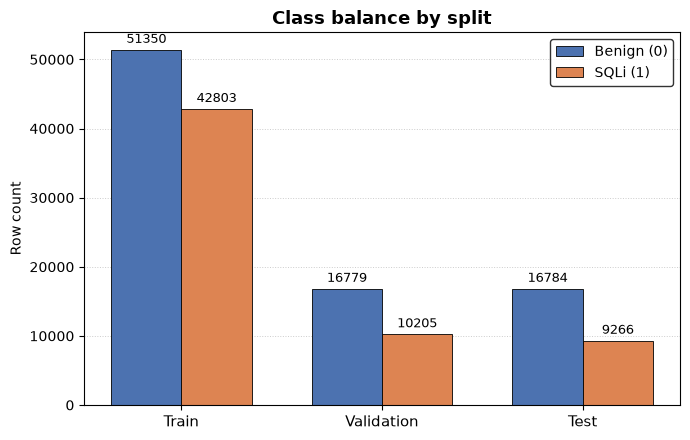

Saved figure: ./output/figures\query_length.png


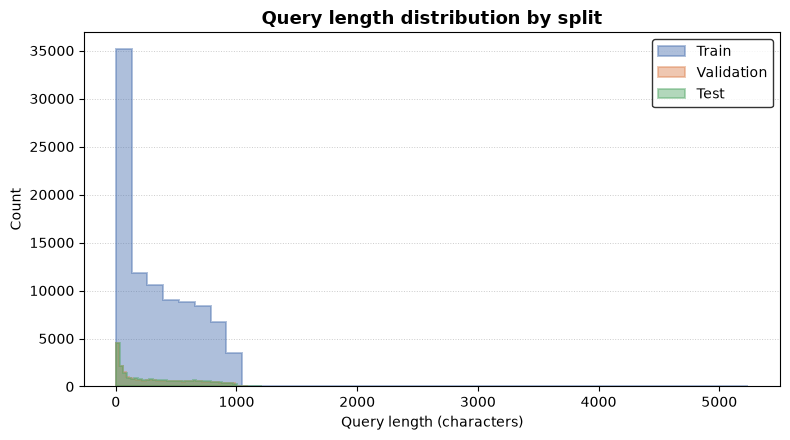


-- Benign examples --
  the film 'nightbreed' is one of the best horror films i have ever seen. overall, i'm not a big fan o
  the story for hare rama hare krishna actually came to dev anand's mind when he saw hippies and their
  atiy
  c/ doctor ferran, 193
  delete from push

-- SQLi examples --
  1" where 6347 = 6347 union all select null,null,null,null,null,null,null,null#
  jk dv1z0r39am1wjiiumia9xrxdowuo87f 110dcc d0ejn372pgx gdvynlkx2bpdzo3fgh5n2iyj8j8iqamt3mgn 7a8a2kxq6
  1'|| ( select 'fdkl' where 4572 = 4572 union all select null,null,null,null,null,null,null,null,null
  okay. yes, this was a very-tight-budget movie with continuity errors (like single scenes obviously f
  1' ) and 2853 = cast ( ( chr ( 113 ) ||chr ( 113 ) ||chr ( 112 ) ||chr/*there's never a dull moment 

Row counts -> train: 94153, validation: 26984, test: 26050


In [7]:
def plot_class_balance(splits, filename="class_balance"):
    """Grouped bar chart: benign vs SQLi count for each split."""
    names = [n for n, d in splits if d is not None]
    benign = [int((d["label"] == 0).sum()) for n, d in splits if d is not None]
    sqli = [int((d["label"] == 1).sum()) for n, d in splits if d is not None]

    x = np.arange(len(names))
    width = 0.35
    fig, ax = plt.subplots(figsize=(7, 4.5))
    b1 = ax.bar(x - width / 2, benign, width, color="#4C72B0", edgecolor="black",
                linewidth=0.6, label="Benign (0)")
    b2 = ax.bar(x + width / 2, sqli, width, color="#DD8452", edgecolor="black",
                linewidth=0.6, label="SQLi (1)")
    ax.bar_label(b1, padding=3, fontsize=9)
    ax.bar_label(b2, padding=3, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([n.capitalize() for n in names], fontsize=11)
    ax.set_ylabel("Row count")
    ax.set_title("Class balance by split", fontsize=13, fontweight="bold")
    ax.legend(frameon=True, edgecolor="black", fontsize=10)
    ax.grid(axis="y", linestyle=":", color="0.8", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


def plot_query_length(splits, filename="query_length"):
    """Overlaid histograms of query character length, one color per split."""
    colors = ["#4C72B0", "#DD8452", "#55A868"]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for (name, d), color in zip(splits, colors):
        if d is None:
            continue
        lengths = d["text"].str.len()
        ax.hist(lengths, bins=40, histtype="stepfilled", alpha=0.45,
                color=color, edgecolor=color, linewidth=1.4, label=name.capitalize())
    ax.set_xlabel("Query length (characters)")
    ax.set_ylabel("Count")
    ax.set_title("Query length distribution by split", fontsize=13, fontweight="bold")
    ax.legend(frameon=True, edgecolor="black", fontsize=10)
    ax.grid(axis="y", linestyle=":", color="0.8", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


def show_sample_queries(df, n=5):
    """Print a few benign and SQLi examples so the labels look sane."""
    for label, name in [(0, "Benign"), (1, "SQLi")]:
        print(f"\n-- {name} examples --")
        sample = df[df["label"] == label]["text"].head(n)
        for s in sample:
            print(f"  {s[:100]}")


_splits = [("train", train_df), ("validation", val_df), ("test", test_df)]

plot_class_balance(_splits)
plot_query_length(_splits)
show_sample_queries(train_df)

print("\nRow counts -> " + ", ".join(
    f"{n}: {len(d)}" for n, d in _splits if d is not None
))

## 4. Feature extraction techniques
The notebook evaluates character TF-IDF, word TF-IDF + PCA, Word2Vec, Keras
Tokenizer, BERT Tokenizer, and RoBERTa Tokenizer. Each function fits only on
training data and transforms train, validation, and test consistently.

Representations are returned as `(Xtr, Xval, Xte, kind[, vocab_size])`, where
`kind` is `"dense"`, `"sparse"`, or `"sequence"`.


In [8]:
def feat_tfidf_char(X_train_text, X_val_text, X_test_text):
    vec = TfidfVectorizer(analyzer="char")
    Xtr = vec.fit_transform(X_train_text)
    Xval = vec.transform(X_val_text)
    Xte = vec.transform(X_test_text)
    return Xtr, Xval, Xte, "sparse"


def feat_tfidf_word_pca(X_train_text, X_val_text, X_test_text, n_components, max_features):
    vec = TfidfVectorizer(analyzer="word", max_features=max_features)
    Xtr = vec.fit_transform(X_train_text).toarray()
    Xval = vec.transform(X_val_text).toarray()
    Xte = vec.transform(X_test_text).toarray()
    n_components = min(n_components, Xtr.shape[0], Xtr.shape[1])
    pca = PCA(n_components=n_components, random_state=SEED)
    Xtr_p = pca.fit_transform(Xtr)
    Xval_p = pca.transform(Xval)
    Xte_p = pca.transform(Xte)
    return Xtr_p, Xval_p, Xte_p, "dense"


def _tokenize_simple(s):
    return re.findall(r"[a-zA-Z_]+|\d+|[^\sa-zA-Z0-9]", s)


def feat_word2vec(X_train_text, X_val_text, X_test_text, params):
    tok_train = [_tokenize_simple(s) for s in X_train_text]
    tok_val = [_tokenize_simple(s) for s in X_val_text]
    tok_test = [_tokenize_simple(s) for s in X_test_text]
    w2v = Word2Vec(sentences=tok_train, **params)

    def sentence_vec(tokens):
        vecs = [w2v.wv[t] for t in tokens if t in w2v.wv]
        if not vecs:
            return np.zeros(params["vector_size"])
        return np.mean(vecs, axis=0)

    Xtr = np.vstack([sentence_vec(t) for t in tok_train])
    Xval = np.vstack([sentence_vec(t) for t in tok_val])
    Xte = np.vstack([sentence_vec(t) for t in tok_test])
    return Xtr, Xval, Xte, "dense"


def feat_keras_tokenizer(X_train_text, X_val_text, X_test_text, vocab_size, max_len):
    tok = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
    tok.fit_on_texts(X_train_text)

    def to_padded(texts):
        seqs = tok.texts_to_sequences(texts)
        return pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post")

    Xtr = to_padded(X_train_text)
    Xval = to_padded(X_val_text)
    Xte = to_padded(X_test_text)
    return Xtr, Xval, Xte, "sequence", tok.num_words or vocab_size


def _hf_call_with_retry(fn, *args, max_retries=4, base_delay=2, **kwargs):
    """Hugging Face Hub calls can hit transient network errors
    (RemoteProtocolError: 'Server disconnected...', read timeouts, etc.)
    even when the model/tokenizer is already cached locally -- this
    transformers version still probes the Hub for chat-template files on
    every from_pretrained()/pipeline() call. Retry with backoff instead of
    losing an entire multi-hour pipeline run to one dropped connection."""
    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            last_err = e
            print(f"    [hf retry {attempt}/{max_retries}] {type(e).__name__}: {e}")
            time.sleep(base_delay * attempt)
    raise last_err


def feat_hf_tokenizer(X_train_text, X_val_text, X_test_text, model_name, max_len):
    from transformers import AutoTokenizer

    tok = _hf_call_with_retry(AutoTokenizer.from_pretrained, model_name)

    def encode(texts):
        enc = tok(
            list(texts),
            padding="max_length",
            truncation=True,
            max_length=max_len,
            return_tensors="np",
        )
        return enc["input_ids"]

    Xtr = encode(X_train_text)
    Xval = encode(X_val_text)
    Xte = encode(X_test_text)
    return Xtr, Xval, Xte, "sequence", tok.vocab_size


## 5. Classical models — every model is tuned with GridSearchCV under
StratifiedKFold instead of fixed, trial-and-error hyperparameters.
(Trained/tuned on Train only; Validation is reserved for the deep models
below; final numbers reported on Test with accuracy **and** imbalance-aware metrics
-- PR-AUC, balanced accuracy, MCC, minority-class recall.)

In [9]:
CV = StratifiedKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=SEED)

CLASSICAL_MODELS = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [10, 20, None], "min_samples_split": [2, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [16, None], "bootstrap": [False, True]},
    ),
    "LDA": (
        LinearDiscriminantAnalysis(),
        {"solver": ["svd", "lsqr"]},
    ),
    "MLP": (
        MLPClassifier(random_state=SEED, max_iter=300),
        {"hidden_layer_sizes": [(128, 64), (256, 128)], "alpha": [1e-4, 1e-3]},
    ),
    # --- New models added for a fuller comparison ---
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=SEED),
        {"C": [0.1, 1.0, 10.0]},
    ),
    "Linear SVM": (
        CalibratedClassifierCV(LinearSVC(random_state=SEED, max_iter=5000), cv=3),
        {"estimator__C": [0.1, 1.0, 10.0]},
    ),
    "KNN": (
        # GridSearchCV already parallelizes model search, so keep KNN itself
        # single-threaded to avoid nested parallelism and unnecessary memory use.
        KNeighborsClassifier(n_jobs=1),
        {"n_neighbors": [5, 11, 21]},
    ),
    "Gaussian Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-9, 1e-7]},
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=SEED),
        {"n_estimators": [100, 200], "learning_rate": [0.5, 1.0]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=SEED),
        {"n_estimators": [100, 200], "max_depth": [3, 5]},
    ),
}
if HAS_XGB:
    CLASSICAL_MODELS["XGBoost"] = (
        XGBClassifier(
            random_state=SEED, eval_metric="logloss", n_jobs=-1, use_label_encoder=False
        ),
        {"n_estimators": [200, 400], "max_depth": [4, 8], "learning_rate": [0.05, 0.1]},
    )

if CONFIG["FAST_MODE"]:
    # Shrink every grid to a single combo so FAST_MODE really is fast —
    # tuning is skipped, only used to sanity-check the pipeline runs.
    CLASSICAL_MODELS = {
        name: (model, {k: [v[0]] for k, v in grid.items()})
        for name, (model, grid) in CLASSICAL_MODELS.items()
    }


def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)


def run_classical_model(name, model, param_grid, Xtr, ytr, Xte, yte):
    t0 = time.time()
    Xtr_d, Xte_d = to_dense(Xtr), to_dense(Xte)
    search = GridSearchCV(
        model, param_grid, cv=CV, scoring="f1", n_jobs=-1, refit=True
    )
    search.fit(Xtr_d, ytr)
    best = search.best_estimator_
    preds = best.predict(Xte_d)
    scores = get_scores(best, Xte_d)

    metrics = compute_metrics(yte, preds, scores, MINORITY_LABEL)
    metrics.update(
        best_params=json.dumps(search.best_params_),
        cv_f1_mean=search.best_score_ * 100,
        fit_seconds=elapsed_since(t0),
    )
    print(f"    {name}: {metrics['fit_seconds']}s, F1={metrics['f1']:.1f}%")
    cm = confusion_matrix(yte, preds)
    return metrics, cm, best

## 6. Deep models (CNN / BiLSTM on sequence inputs — unchanged architecture
from the paper, but now validated against the dataset's real Validation
split, with early stopping added as a training-quality improvement)

In [10]:
def build_cnn(vocab_size, max_len, embed_dim=128, num_filters=128, kernel_sizes=(3, 4, 5)):
    model = Sequential()
    model.add(Embedding(input_dim=vocab_size + 1, output_dim=embed_dim, input_length=max_len))
    model.add(Conv1D(num_filters, kernel_sizes[0], activation="relu"))
    model.add(GlobalMaxPooling1D())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def build_bilstm(vocab_size, max_len, embed_dim=128, lstm_units=64):
    model = Sequential()
    model.add(Embedding(input_dim=vocab_size + 1, output_dim=embed_dim, input_length=max_len))
    model.add(Bidirectional(LSTM(lstm_units)))
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def run_deep_model(build_fn, vocab_size, Xtr, ytr, Xval, yval, Xte, yte, max_len,
                    epochs=10, batch_size=128):
    t0 = time.time()
    model = build_fn(vocab_size, max_len)
    es = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    model.fit(
        Xtr,
        ytr,
        validation_data=(Xval, yval),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0,
    )
    probs = model.predict(Xte, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)

    metrics = compute_metrics(yte, preds, probs, MINORITY_LABEL)
    metrics.update(
        best_params=f"early_stopping(patience=2),epochs<={epochs}",
        cv_f1_mean=np.nan,
        fit_seconds=elapsed_since(t0),
    )
    print(f"    fit time: {metrics['fit_seconds']}s, F1={metrics['f1']:.1f}%")
    cm = confusion_matrix(yte, preds)
    return metrics, cm, probs

## 7. Orchestration — build every feature extraction technique once, then run
every classical model + (where sensible) the deep models against it.
Results are appended to a CSV so a Kaggle timeout doesn't lose progress, and
per-technique + total wall-clock time is tracked and printed.

> **Note:** results are cached by *(technique, model)* in `results_extended_v2.csv`. After changing the data
> cleaning procedure or `FAST_MODE`, delete that file (and `results_imbalance.csv`) so stale rows are not reused.

In [11]:
RESULTS_COLUMNS = [
    "technique", "model", "accuracy", "precision", "recall", "f1",
    "balanced_accuracy", "mcc", "pr_auc", "roc_auc", "minority_recall",
    "best_params", "cv_f1_mean", "fit_seconds",
]

# A results file written with a different schema (e.g. by the old pipeline) must not be mixed with
# the new one -- and rows produced with the OLD leakage procedure must not be reused as "cached".
if os.path.exists(CONFIG["RESULTS_CSV"]):
    _hdr = list(pd.read_csv(CONFIG["RESULTS_CSV"], nrows=0).columns)
    if _hdr != RESULTS_COLUMNS:
        os.replace(CONFIG["RESULTS_CSV"], CONFIG["RESULTS_CSV"] + ".old")
        print("Existing results file had a different schema -> moved to .old")



def append_result(row, csv_path=CONFIG["RESULTS_CSV"]):
    row = dict(row)  # don't mutate caller's dict
    # stringify anything that isn't a plain scalar (e.g. GridSearchCV best_params_
    # dicts), so commas/quotes inside them can't desync the column count on append
    if "best_params" in row and not isinstance(row["best_params"], (str, float, int, type(None))):
        row["best_params"] = str(row["best_params"])

    df_row = pd.DataFrame([row])
    # enforce a fixed column schema every time so appended rows always line up
    # with whatever header was written first, regardless of dict key order
    for col in RESULTS_COLUMNS:
        if col not in df_row.columns:
            df_row[col] = np.nan
    df_row = df_row[RESULTS_COLUMNS]

    write_header = not os.path.exists(csv_path)
    df_row.to_csv(csv_path, mode="a", header=write_header, index=False)


def already_done(technique, model_name, csv_path=CONFIG["RESULTS_CSV"]):
    if not os.path.exists(csv_path):
        return False
    done = _read_csv_robust(csv_path)
    return ((done["technique"] == technique) & (done["model"] == model_name)).any()


confusion_matrices = {}  # (technique, model_name) -> cm

FEATURE_TECHNIQUES = [
    "TF-IDF (char)",
    "TF-IDF+PCA(n=15)",
    "TF-IDF+PCA(n=512)",
    "Word2Vec",
    "Tokenizer",
]
if CONFIG["RUN_TRANSFORMER_TOKENIZERS"]:
    FEATURE_TECHNIQUES += [
        "BERT Tokenizer",
        "RoBERTa Tokenizer",
    ]

for technique in FEATURE_TECHNIQUES:
    technique_t0 = time.time()
    print(f"\n=== Building features: {technique} ===")
    vocab_size = None

    if technique == "TF-IDF (char)":
        Xtr, Xval, Xte, kind = feat_tfidf_char(X_train_text, X_val_text, X_test_text)
    elif technique == "TF-IDF+PCA(n=15)":
        Xtr, Xval, Xte, kind = feat_tfidf_word_pca(
            X_train_text, X_val_text, X_test_text, 15, CONFIG["TFIDF_WORD_MAX_FEATURES"]
        )
    elif technique == "TF-IDF+PCA(n=512)":
        Xtr, Xval, Xte, kind = feat_tfidf_word_pca(
            X_train_text, X_val_text, X_test_text, 512, CONFIG["TFIDF_WORD_MAX_FEATURES"]
        )
    elif technique == "Word2Vec":
        Xtr, Xval, Xte, kind = feat_word2vec(
            X_train_text, X_val_text, X_test_text, CONFIG["WORD2VEC_PARAMS"]
        )
    elif technique == "Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_keras_tokenizer(
            X_train_text, X_val_text, X_test_text, CONFIG["TOKENIZER_VOCAB"], CONFIG["MAX_SEQ_LEN"]
        )
    elif technique == "BERT Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_hf_tokenizer(
            X_train_text, X_val_text, X_test_text, "bert-base-uncased", CONFIG["MAX_SEQ_LEN"]
        )
    elif technique == "RoBERTa Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_hf_tokenizer(
            X_train_text, X_val_text, X_test_text, "roberta-base", CONFIG["MAX_SEQ_LEN"]
        )
    else:
        continue

    print(f"  feature build time: {elapsed_since(technique_t0)}s")

    # --- classical models on every technique (dense/sparse-compatible) ---
    for model_name, (model, grid) in CLASSICAL_MODELS.items():
        if already_done(technique, model_name):
            print(f"  skip (cached): {model_name}")
            continue
        try:
            print(f"  fitting: {model_name}")
            metrics, cm, _ = run_classical_model(
                model_name, model, grid, Xtr, y_train, Xte, y_test
            )
            row = dict(technique=technique, model=model_name, **metrics)
            append_result(row)
            confusion_matrices[(technique, model_name)] = cm
        except Exception as e:
            print(f"  FAILED {model_name} on {technique}: {e}")

    # --- deep models only where the representation is a padded token sequence ---
    if kind == "sequence" and vocab_size:
        for dm_name, build_fn in [("CNN", build_cnn), ("BiLSTM", build_bilstm)]:
            if already_done(technique, dm_name):
                print(f"  skip (cached): {dm_name}")
                continue
            try:
                print(f"  fitting: {dm_name}")
                metrics, cm, _ = run_deep_model(
                    build_fn, vocab_size, Xtr, y_train, Xval, y_val, Xte, y_test,
                    CONFIG["MAX_SEQ_LEN"], epochs=CONFIG["DEEP_EPOCHS"],
                )
                row = dict(technique=technique, model=dm_name, **metrics)
                append_result(row)
                confusion_matrices[(technique, dm_name)] = cm
            except Exception as e:
                print(f"  FAILED {dm_name} on {technique}: {e}")
    TECHNIQUE_TIMES[technique] = elapsed_since(technique_t0)
    print(f"  >> '{technique}' total time: {TECHNIQUE_TIMES[technique]}s "
          f"({fmt_minutes(TECHNIQUE_TIMES[technique])})")


=== Building features: TF-IDF (char) ===
  feature build time: 7.3s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  >> 'TF-IDF (char)' total time: 7.3s (0.1 min)

=== Building features: TF-IDF+PCA(n=15) ===
  feature build time: 26.0s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  >> 'TF-IDF+PCA(n=15)' total time: 26.0s (0.4 min)

=== Building features: TF-IDF+PCA(n=512) ===
  feature build time: 66.0s
  skip (cached): Decision Tree
  skip (cached): Random F

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


  feature build time: 41.7s
  fitting: Decision Tree
    Decision Tree: 58.6s, F1=90.4%
  fitting: Random Forest
    Random Forest: 1039.3s, F1=93.6%
  fitting: LDA
    LDA: 12.9s, F1=60.8%
  fitting: MLP
    MLP: 2120.8s, F1=66.2%
  fitting: Logistic Regression
    Logistic Regression: 31.6s, F1=59.6%
  fitting: Linear SVM
    Linear SVM: 94.6s, F1=60.0%
  fitting: KNN
    KNN: 331.8s, F1=46.2%
  fitting: Gaussian Naive Bayes
    Gaussian Naive Bayes: 2.0s, F1=61.5%
  fitting: AdaBoost
    AdaBoost: 652.8s, F1=91.0%
  fitting: Gradient Boosting
    Gradient Boosting: 2256.1s, F1=95.1%
  fitting: XGBoost
    XGBoost: 287.1s, F1=95.7%
  fitting: CNN
    fit time: 137.5s, F1=98.7%
  fitting: BiLSTM
    fit time: 418.6s, F1=98.2%
  >> 'BERT Tokenizer' total time: 7485.5s (124.8 min)

=== Building features: RoBERTa Tokenizer ===
  feature build time: 29.9s
  fitting: Decision Tree
    Decision Tree: 72.9s, F1=85.5%
  fitting: Random Forest
    Random Forest: 1173.9s, F1=91.9%
  fitting: LD

## 7b. Class-imbalance experiments
**Motivation.** SQL-injection traffic is rare in practice, so a classifier that looks excellent on a (near-)balanced
benchmark can be unusable under realistic prevalence. This section studies the effect of imbalance explicitly.

**Design.**
- *Imbalance ratios:* starting from the cleaned splits, the minority class (SQLi, label 1) is randomly
  sub-sampled to a target share of 20 %, 10 %, 5 % and 1 % (plus the native distribution). The **same** share is
  applied to train, validation and test so the evaluation prevalence matches the training prevalence. All majority-class
  rows are kept. If the native minority share is already below a target, the native share is used.
- *Repetitions:* each setting is repeated over several seeds (different minority sub-samples); results are reported
  as mean ± std.
- *Imbalance-aware strategies (applied to the training data only):*
  `none` (baseline) · `class_weight` (cost-sensitive, "balanced" sample weights) · `oversample` (random
  over-sampling of the minority class to parity) · `undersample` (random under-sampling of the majority class to parity).
  Every strategy is additionally evaluated with a **tuned decision threshold** (`threshold_mode = tuned_mcc`) chosen to
  maximise MCC on the *validation* split (never the test split).
- *Metrics:* PR-AUC, balanced accuracy, MCC, minority-class recall, ROC-AUC, precision, recall, F1 and accuracy
  (accuracy is kept to show how misleading it becomes). In this experiment `minority_recall` is the recall of the
  SQLi class, i.e. identical to `recall`.
- *Leakage safety:* feature extractors (TF-IDF, tokenizer vocabulary) are fitted on the (imbalanced) training
  split only; resampling is applied after feature extraction and only to training rows; hyper-parameters are fixed
  (no grid search) so that resampled duplicates can never leak across CV folds.

In [12]:
# ------------------------------------------------------------------ helpers
def build_features(technique, Xtr_t, Xval_t, Xte_t):
    """Same feature builders as Section 4, fitted on the given TRAIN texts only.
    Returns (Xtr, Xval, Xte, kind, vocab_size)."""
    if technique == "TF-IDF (char)":
        return (*feat_tfidf_char(Xtr_t, Xval_t, Xte_t), None)
    if technique.startswith("TF-IDF+PCA"):
        n = int(technique.split("n=")[1].rstrip(")"))
        return (*feat_tfidf_word_pca(Xtr_t, Xval_t, Xte_t, n, CONFIG["TFIDF_WORD_MAX_FEATURES"]), None)
    if technique == "Word2Vec":
        return (*feat_word2vec(Xtr_t, Xval_t, Xte_t, CONFIG["WORD2VEC_PARAMS"]), None)
    if technique == "Tokenizer":
        return feat_keras_tokenizer(Xtr_t, Xval_t, Xte_t, CONFIG["TOKENIZER_VOCAB"], CONFIG["MAX_SEQ_LEN"])
    if technique == "BERT Tokenizer":
        return feat_hf_tokenizer(Xtr_t, Xval_t, Xte_t, "bert-base-uncased", CONFIG["MAX_SEQ_LEN"])
    if technique == "RoBERTa Tokenizer":
        return feat_hf_tokenizer(Xtr_t, Xval_t, Xte_t, "roberta-base", CONFIG["MAX_SEQ_LEN"])
    raise ValueError(technique)


def subsample_to_share(texts, y, share, rng, minority_label=1):
    """Randomly drop minority-class rows so that they make up `share` of the result.
    All majority rows are kept. share=None (or a share above the native one) -> unchanged."""
    texts, y = np.asarray(texts), np.asarray(y)
    if share is None:
        return texts, y
    pos = np.flatnonzero(y == minority_label)
    neg = np.flatnonzero(y != minority_label)
    n_pos = min(int(round(share / (1.0 - share) * len(neg))), len(pos))
    idx = np.concatenate([neg, rng.choice(pos, size=n_pos, replace=False)])
    rng.shuffle(idx)
    return texts[idx], y[idx]


def resample_train_indices(y, strategy, rng):
    """Row indices of the TRAIN split after random over-/under-sampling to class parity."""
    y = np.asarray(y)
    idx = np.arange(len(y))
    classes, counts = np.unique(y, return_counts=True)
    if strategy not in ("oversample", "undersample") or len(classes) < 2:
        return idx
    minority = idx[y == classes[np.argmin(counts)]]
    majority = idx[y == classes[np.argmax(counts)]]
    if strategy == "oversample":
        extra = rng.choice(minority, size=len(majority) - len(minority), replace=True)
        out = np.concatenate([idx, extra])
    else:
        out = np.concatenate([minority, rng.choice(majority, size=len(minority), replace=False)])
    rng.shuffle(out)
    return out


IMB_CLASSICAL_FACTORIES = {
    "Logistic Regression": lambda s: LogisticRegression(max_iter=1000, C=10.0, random_state=s),
    "Linear SVM": lambda s: CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=5000, random_state=s), cv=3),
    "Random Forest": lambda s: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=s),
}
if HAS_XGB:
    IMB_CLASSICAL_FACTORIES["XGBoost"] = lambda s: XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1, eval_metric="logloss", n_jobs=-1, random_state=s)
IMB_DEEP_BUILDERS = {"CNN": build_cnn, "BiLSTM": build_bilstm}

IMB_COLUMNS = [
    "seed", "target_share", "train_pos_share", "val_pos_share", "test_pos_share",
    "n_train", "n_val", "n_test", "n_test_pos",
    "technique", "model", "strategy", "threshold_mode", "threshold",
    "accuracy", "precision", "recall", "f1", "balanced_accuracy", "mcc",
    "pr_auc", "roc_auc", "minority_recall", "fit_seconds",
]


def _fit_classical(factory, Xtr, ytr, Xval, Xte, strategy, seed):
    rng = np.random.RandomState(seed)
    Xtr_d, Xval_d, Xte_d = to_dense(Xtr), to_dense(Xval), to_dense(Xte)
    idx = resample_train_indices(ytr, strategy, rng)
    Xr, yr = Xtr_d[idx], np.asarray(ytr)[idx]
    fit_kw = {}
    if strategy == "class_weight":
        fit_kw["sample_weight"] = compute_sample_weight("balanced", yr)
    t0 = time.time()
    model = factory(seed)
    model.fit(Xr, yr, **fit_kw)
    return get_scores(model, Xval_d), get_scores(model, Xte_d), elapsed_since(t0)


def _fit_deep(build_fn, vocab_size, Xtr, ytr, Xval, yval, Xte, strategy, seed):
    tf.keras.backend.clear_session()
    tf.random.set_seed(seed)
    rng = np.random.RandomState(seed)
    idx = resample_train_indices(ytr, strategy, rng)
    Xr, yr = np.asarray(Xtr)[idx], np.asarray(ytr)[idx]
    cw = None
    if strategy == "class_weight":
        classes, counts = np.unique(yr, return_counts=True)
        cw = {int(c): len(yr) / (len(classes) * n) for c, n in zip(classes, counts)}
    t0 = time.time()
    model = build_fn(vocab_size, CONFIG["MAX_SEQ_LEN"])
    es = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    model.fit(Xr, yr, validation_data=(Xval, yval), epochs=CONFIG["DEEP_EPOCHS"], batch_size=128,
              callbacks=[es], class_weight=cw, verbose=0)
    return (model.predict(Xval, verbose=0).ravel(), model.predict(Xte, verbose=0).ravel(), elapsed_since(t0))


def _make_rows(base, y_val, s_val, y_te, s_te):
    """Two rows per fit: default 0.5 threshold, and the MCC-tuned (validation) threshold."""
    rows = []
    for mode, thr in [("default", 0.5), ("tuned_mcc", tune_threshold(y_val, s_val))]:
        m = compute_metrics(y_te, (s_te >= thr).astype(int), s_te, CONFIG["IMBALANCE_MINORITY_LABEL"])
        rows.append(dict(base, threshold_mode=mode, threshold=thr, **m))
    return rows


def _append_imb(rows):
    df = pd.DataFrame(rows)
    for c in IMB_COLUMNS:
        if c not in df.columns:
            df[c] = np.nan
    df = df[IMB_COLUMNS]
    path = CONFIG["IMBALANCE_CSV"]
    df.to_csv(path, mode="a", header=not os.path.exists(path), index=False)


# ------------------------------------------------------------------ driver
def run_imbalance_experiments():
    t_start = time.time()
    path = CONFIG["IMBALANCE_CSV"]
    done = set()
    if os.path.exists(path):
        prev = pd.read_csv(path, dtype={"target_share": str})
        done = set(zip(prev["seed"], prev["target_share"], prev["technique"], prev["model"], prev["strategy"]))

    pos_lab = CONFIG["IMBALANCE_MINORITY_LABEL"]
    for seed in CONFIG["IMBALANCE_SEEDS"]:
        for share in CONFIG["IMBALANCE_SHARES"]:
            share_lbl = "native" if share is None else f"{share:g}"
            rng = np.random.RandomState(seed)
            tr_t, tr_y = subsample_to_share(X_train_text, y_train, share, rng, pos_lab)
            va_t, va_y = subsample_to_share(X_val_text, y_val, share, rng, pos_lab)
            te_t, te_y = subsample_to_share(X_test_text, y_test, share, rng, pos_lab)
            n_te_pos = int((te_y == pos_lab).sum())
            print(f"\n##### seed={seed} share={share_lbl}: train={len(tr_y)} (pos {np.mean(tr_y == pos_lab):.3%}), "
                  f"val={len(va_y)}, test={len(te_y)} (pos {n_te_pos})")
            if n_te_pos < 30 or (tr_y == pos_lab).sum() < 30:
                print("  [warn] very few minority samples -> metrics at this ratio will be noisy")

            for technique in CONFIG["IMBALANCE_TECHNIQUES"]:
                plan = []
                for m in CONFIG["IMBALANCE_CLASSICAL_MODELS"]:
                    if m in IMB_CLASSICAL_FACTORIES:
                        plan += [("classical", m, s) for s in CONFIG["IMBALANCE_STRATEGIES"]]
                plan_deep = [("deep", m, s) for m in CONFIG["IMBALANCE_DEEP_MODELS"]
                             for s in CONFIG["IMBALANCE_STRATEGIES"]]
                todo_c = [p for p in plan if (seed, share_lbl, technique, p[1], p[2]) not in done]
                todo_d = [p for p in plan_deep if (seed, share_lbl, technique, p[1], p[2]) not in done]
                if not todo_c and not todo_d:
                    continue

                print(f"  -- features: {technique}")
                try:
                    Xtr, Xval, Xte, kind, vocab = build_features(technique, tr_t, va_t, te_t)
                except Exception as e:
                    print(f"  FAILED features {technique}: {e}")
                    continue

                base0 = dict(seed=seed, target_share=share_lbl,
                             train_pos_share=float(np.mean(tr_y == pos_lab)),
                             val_pos_share=float(np.mean(va_y == pos_lab)),
                             test_pos_share=float(np.mean(te_y == pos_lab)),
                             n_train=len(tr_y), n_val=len(va_y), n_test=len(te_y), n_test_pos=n_te_pos,
                             technique=technique)

                for _, mname, strat in todo_c:
                    try:
                        s_val, s_te, secs = _fit_classical(IMB_CLASSICAL_FACTORIES[mname], Xtr, tr_y, Xval, Xte, strat, seed)
                        rows = _make_rows(dict(base0, model=mname, strategy=strat, fit_seconds=secs), va_y, s_val, te_y, s_te)
                        _append_imb(rows)
                        print(f"     {mname:<20s} {strat:<12s} PR-AUC={rows[0]['pr_auc']:.1f} "
                              f"MCC={rows[0]['mcc']:.3f} (tuned MCC={rows[1]['mcc']:.3f})")
                    except Exception as e:
                        print(f"     FAILED {mname}/{strat}: {e}")

                if kind == "sequence" and vocab:
                    for _, mname, strat in todo_d:
                        try:
                            s_val, s_te, secs = _fit_deep(IMB_DEEP_BUILDERS[mname], vocab, Xtr, tr_y, Xval, va_y, Xte, strat, seed)
                            rows = _make_rows(dict(base0, model=mname, strategy=strat, fit_seconds=secs), va_y, s_val, te_y, s_te)
                            _append_imb(rows)
                            print(f"     {mname:<20s} {strat:<12s} PR-AUC={rows[0]['pr_auc']:.1f} "
                                  f"MCC={rows[0]['mcc']:.3f} (tuned MCC={rows[1]['mcc']:.3f})")
                        except Exception as e:
                            print(f"     FAILED {mname}/{strat}: {e}")

    TECHNIQUE_TIMES["Imbalance experiments"] = elapsed_since(t_start)
    print(f"\n>> imbalance experiments: {fmt_minutes(TECHNIQUE_TIMES['Imbalance experiments'])}")
    return pd.read_csv(path, dtype={"target_share": str}) if os.path.exists(path) else pd.DataFrame(columns=IMB_COLUMNS)


imbalance_df = run_imbalance_experiments()


##### seed=42 share=native: train=94153 (pos 45.461%), val=26984, test=26050 (pos 9266)
  -- features: TF-IDF (char)
     Logistic Regression  none         PR-AUC=95.7 MCC=0.826 (tuned MCC=0.830)
     Logistic Regression  class_weight PR-AUC=95.7 MCC=0.824 (tuned MCC=0.830)
     Logistic Regression  oversample   PR-AUC=95.7 MCC=0.825 (tuned MCC=0.830)
     Logistic Regression  undersample  PR-AUC=95.7 MCC=0.824 (tuned MCC=0.830)
     Linear SVM           none         PR-AUC=95.5 MCC=0.818 (tuned MCC=0.825)
     Linear SVM           class_weight PR-AUC=95.5 MCC=0.815 (tuned MCC=0.824)
     Linear SVM           oversample   PR-AUC=95.5 MCC=0.816 (tuned MCC=0.825)
     Linear SVM           undersample  PR-AUC=95.5 MCC=0.817 (tuned MCC=0.826)
     Random Forest        none         PR-AUC=99.9 MCC=0.984 (tuned MCC=0.984)
     Random Forest        class_weight PR-AUC=99.9 MCC=0.984 (tuned MCC=0.984)
     Random Forest        oversample   PR-AUC=99.9 MCC=0.984 (tuned MCC=0.983)
     Random F

## 8. Runtime summary — printed so you can see exactly where the time went

In [13]:
print("\n=== Runtime summary (seconds) by feature-extraction technique ===")
for tech, secs in TECHNIQUE_TIMES.items():
    print(f"  {tech:<22} {secs:>8.1f}s  ({fmt_minutes(secs)})")

TOTAL_SECONDS = elapsed_since(PIPELINE_START)
print(f"\nTOTAL PIPELINE RUNTIME: {TOTAL_SECONDS:.1f}s ({fmt_minutes(TOTAL_SECONDS)})")

if os.path.exists(CONFIG["RESULTS_CSV"]):
    _r = pd.read_csv(CONFIG["RESULTS_CSV"])
    if "fit_seconds" in _r.columns:
        print("\nSlowest 5 (technique, model) fits:")
        print(
            _r.sort_values("fit_seconds", ascending=False)[
                ["technique", "model", "fit_seconds", "f1"]
            ].head(5).to_string(index=False)
        )


=== Runtime summary (seconds) by feature-extraction technique ===
  TF-IDF (char)               7.3s  (0.1 min)
  TF-IDF+PCA(n=15)           26.0s  (0.4 min)
  TF-IDF+PCA(n=512)          66.1s  (1.1 min)
  Word2Vec                 5324.6s  (88.7 min)
  Tokenizer                6963.4s  (116.1 min)
  BERT Tokenizer           7485.5s  (124.8 min)
  RoBERTa Tokenizer        9196.2s  (153.3 min)
  Imbalance experiments   12599.3s  (210.0 min)

TOTAL PIPELINE RUNTIME: 42162.5s (702.7 min)

Slowest 5 (technique, model) fits:
        technique             model  fit_seconds        f1
TF-IDF+PCA(n=512) Gradient Boosting      17866.5 96.327434
TF-IDF+PCA(n=512)     Random Forest       6231.8 95.537764
 TF-IDF+PCA(n=15)               MLP       5473.2 95.743389
TF-IDF+PCA(n=512)          AdaBoost       5160.7 91.048536
         Word2Vec Gradient Boosting       3877.7 95.865491


## 9. Final figures
Comparison charts (metric-by-model-technique bars and the leaderboard) use color for readability now that there are up to 11 series on one axis. Confusion matrices stay strictly grayscale.

       technique                model   accuracy  precision     recall  \
0  TF-IDF (char)        Decision Tree  98.706334  98.595842  97.755234   
1  TF-IDF (char)        Random Forest  99.274472  99.315441  98.640190   
2  TF-IDF (char)                  LDA  90.399232  92.191593  79.764731   
3  TF-IDF (char)                  MLP  99.182342  98.855909  98.845241   
4  TF-IDF (char)  Logistic Regression  92.084453  92.010730  85.139219   

          f1  balanced_accuracy       mcc     pr_auc    roc_auc  \
0  98.173739          98.493323  0.971743  97.552705  98.217902   
1  98.976664          99.132416  0.984161  99.902244  99.923590   
2  85.529133          88.017494  0.788619  93.297156  94.982474   
3  98.850575          99.106843  0.982161  99.742794  99.788610   
4  88.441704          90.528975  0.825804  95.671463  96.696244   

   minority_recall                                        best_params  \
0        97.755234          {"max_depth": 20, "min_samples_split": 2}   
1     

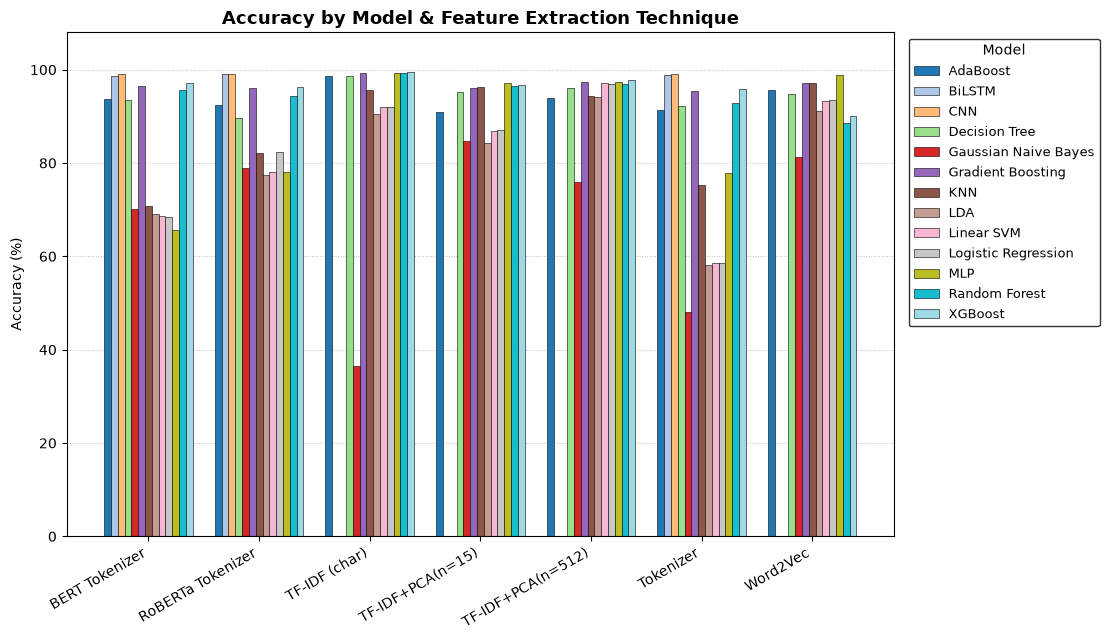

Saved figure: ./output/figures\precision_by_model_technique.png


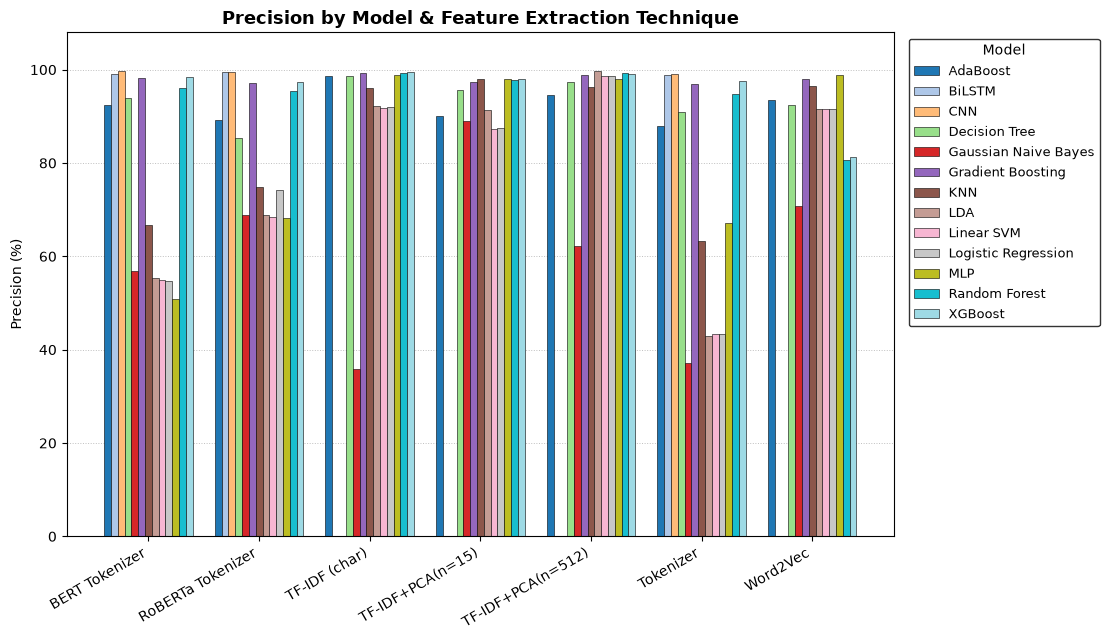

Saved figure: ./output/figures\recall_by_model_technique.png


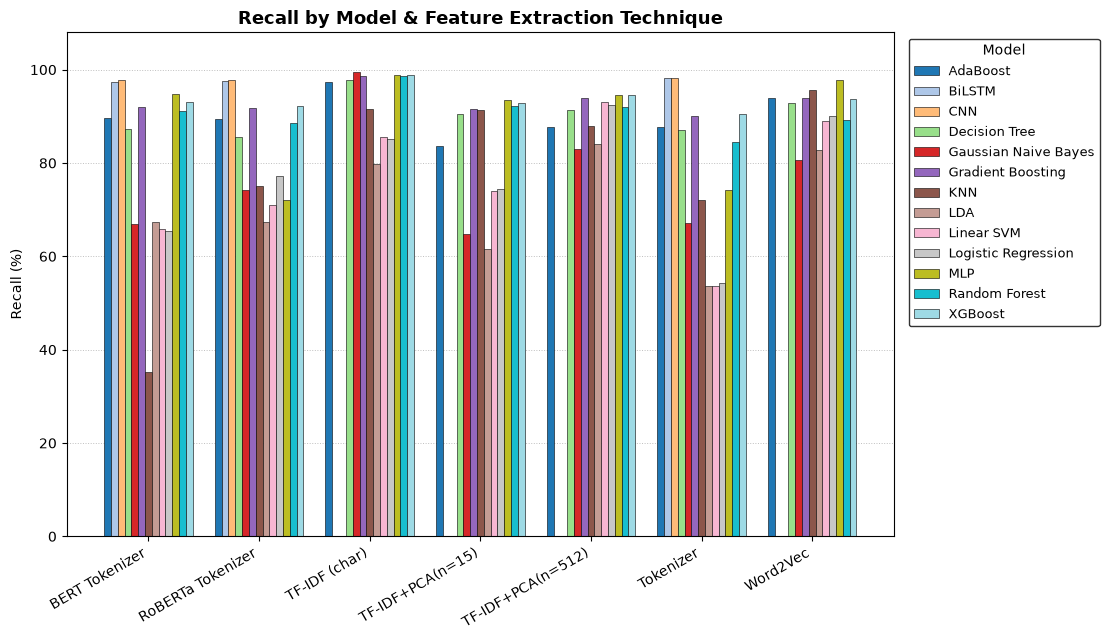

Saved figure: ./output/figures\f1_by_model_technique.png


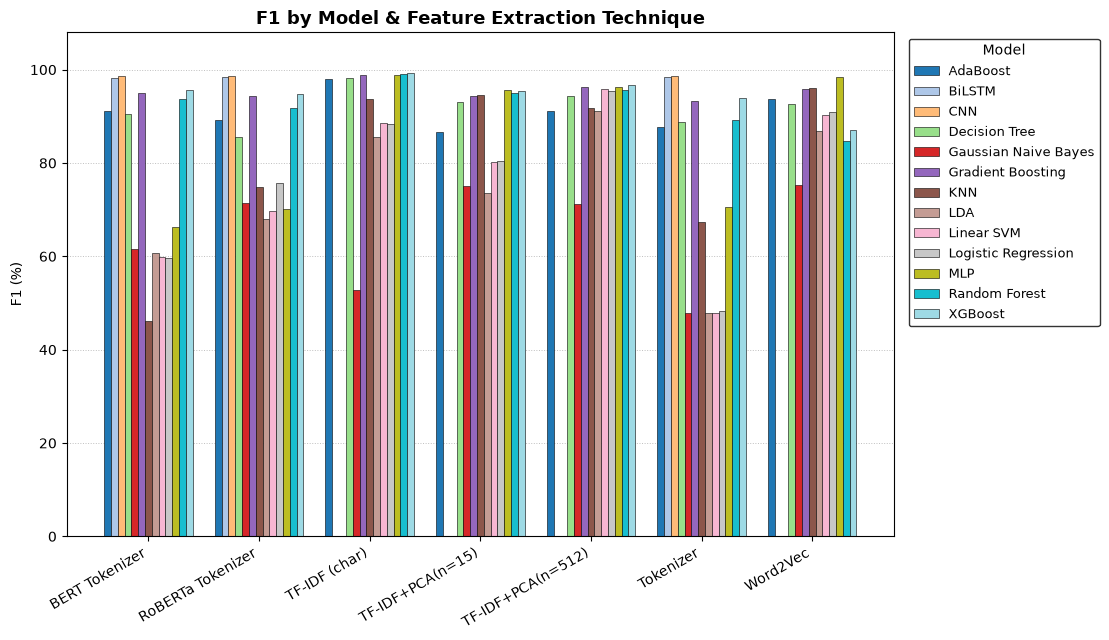

Saved figure: ./output/figures\balanced_accuracy_by_model_technique.png


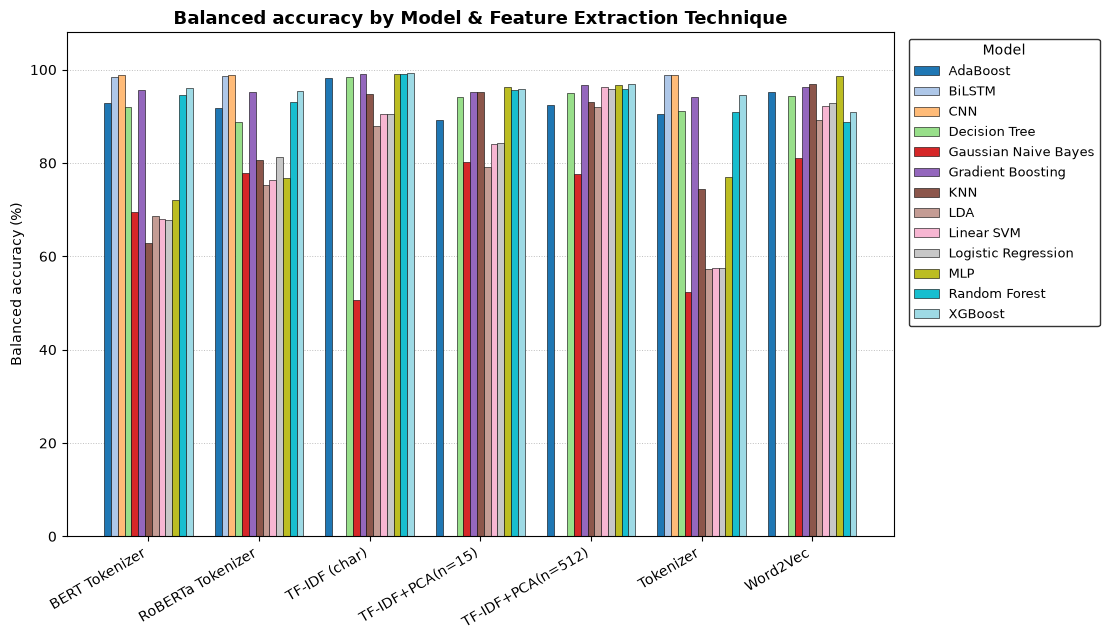

Saved figure: ./output/figures\mcc_by_model_technique.png


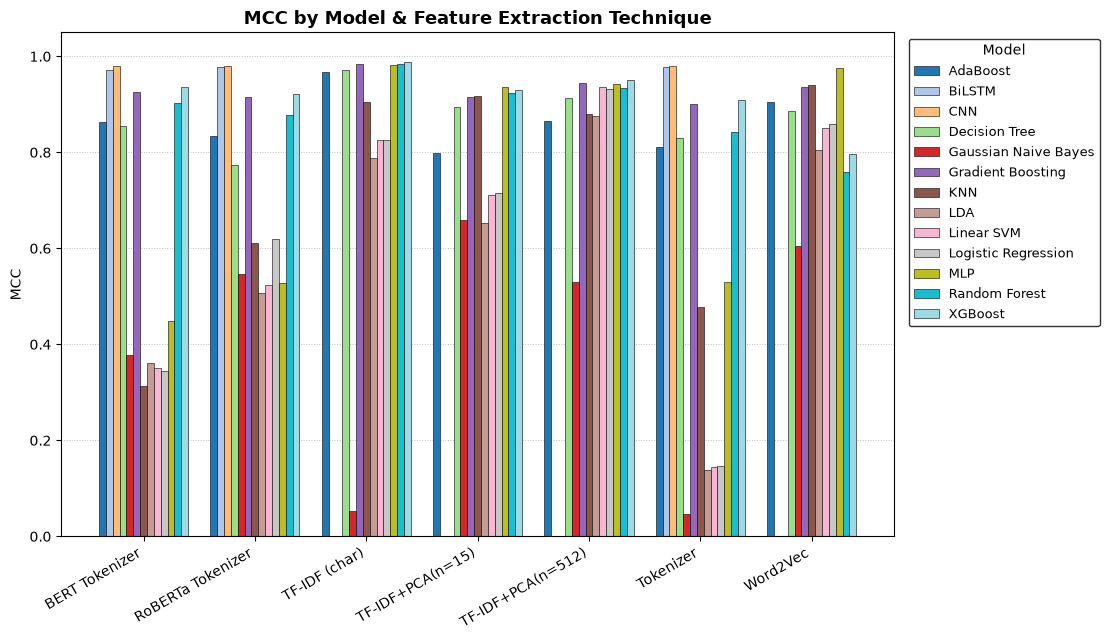

Saved figure: ./output/figures\pr_auc_by_model_technique.png


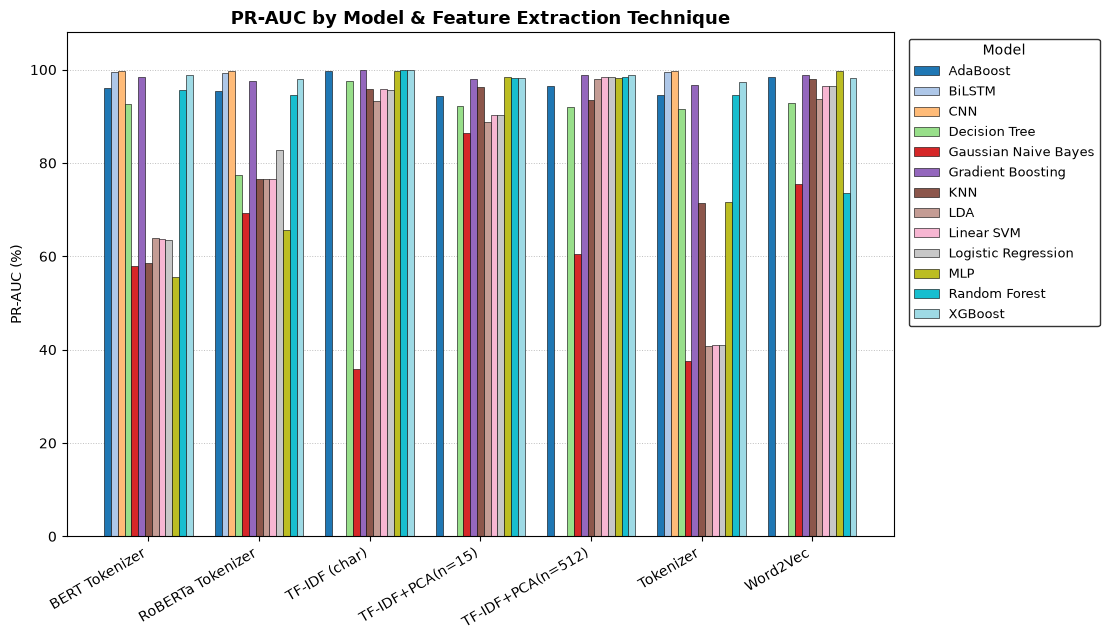

Saved figure: ./output/figures\minority_recall_by_model_technique.png


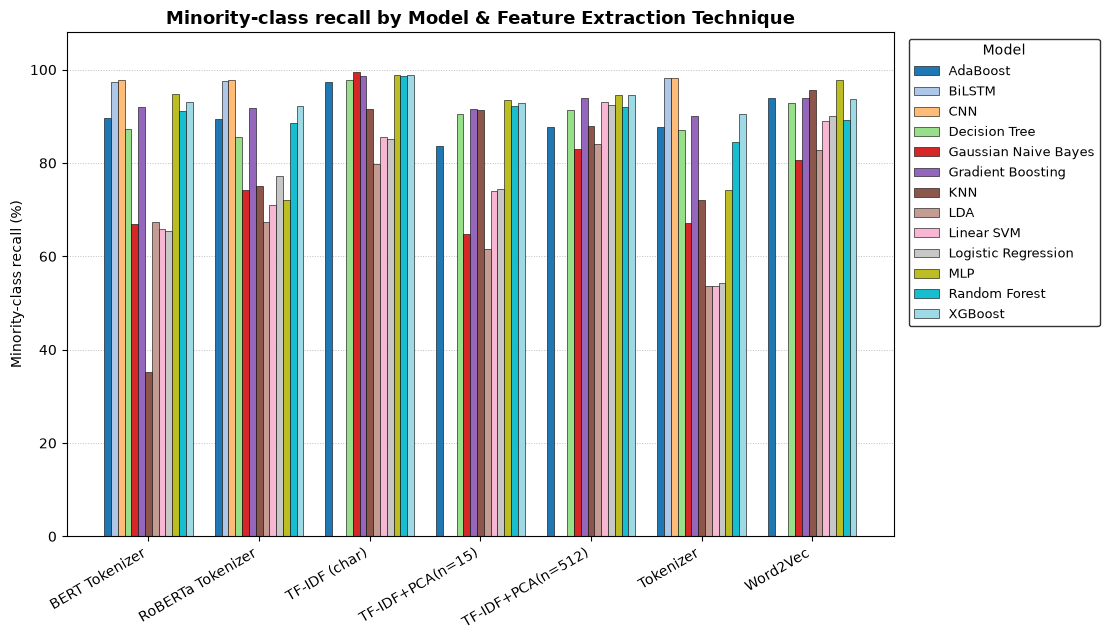

Saved figure: ./output/figures\cm_CNN_BERT_Tokenizer.png


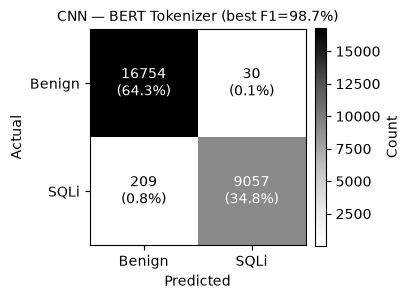

Saved figure: ./output/figures\cm_BiLSTM_RoBERTa_Tokenizer.png


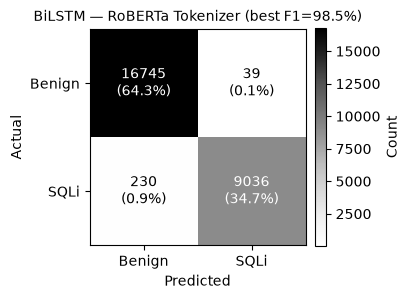

Saved figure: ./output/figures\leaderboard.png


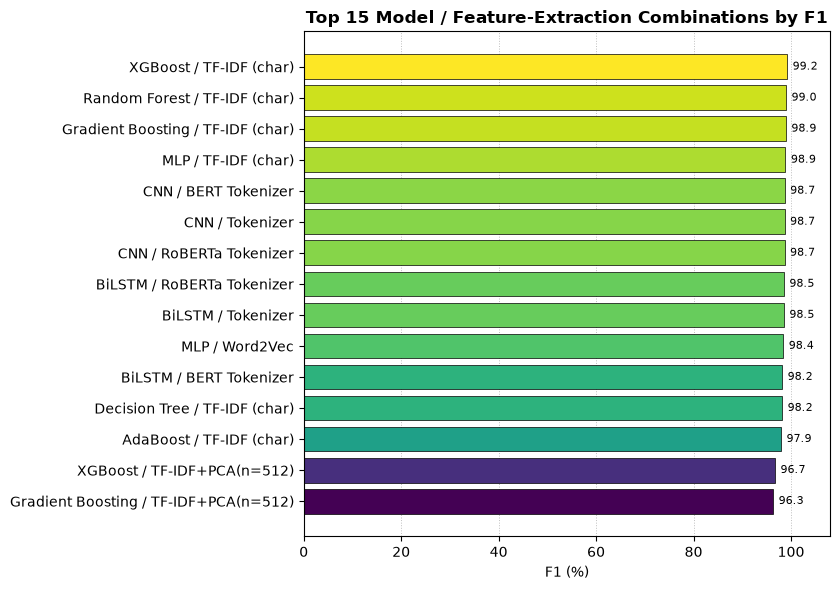

Saved figure: ./output/figures\leaderboard_pr_auc.png


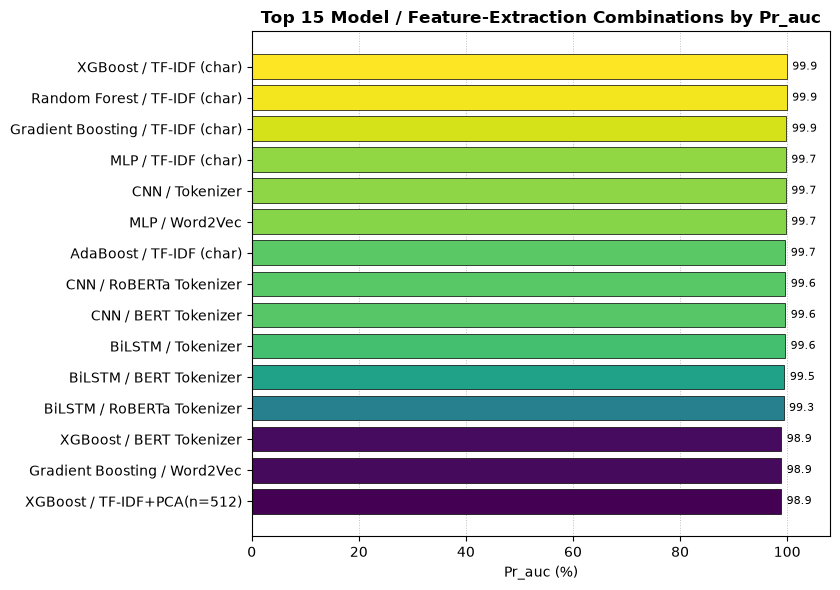

Saved figure: ./output/figures\leaderboard_balanced_accuracy.png


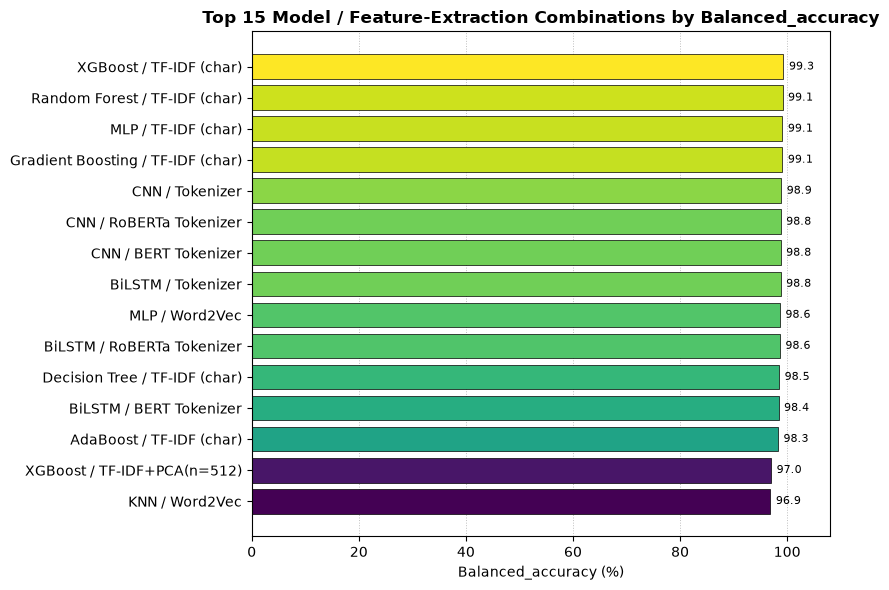


Top 10 combinations by MCC (imbalance-aware metrics, native test distribution):
        technique             model  accuracy  balanced_accuracy   mcc  pr_auc  minority_recall     f1
    TF-IDF (char)           XGBoost    99.432             99.315 0.988  99.919           98.910 99.199
    TF-IDF (char)     Random Forest    99.274             99.132 0.984  99.902           98.640 98.977
    TF-IDF (char) Gradient Boosting    99.251             99.102 0.984  99.853           98.586 98.944
    TF-IDF (char)               MLP    99.182             99.107 0.982  99.743           98.845 98.851
   BERT Tokenizer               CNN    99.083             98.783 0.980  99.642           97.744 98.698
RoBERTa Tokenizer               CNN    99.063             98.787 0.980  99.646           97.831 98.672
        Tokenizer               CNN    99.063             98.889 0.980  99.742           98.284 98.678
RoBERTa Tokenizer            BiLSTM    98.967             98.643 0.977  99.320           97.518

In [14]:
results_df = pd.read_csv(CONFIG["RESULTS_CSV"])
print(results_df.head())

# From here on, only the confusion matrices stay strictly grayscale (they're
# meant to be printable/copy-safe). The comparison charts below use color --
# with 9-11 series on one axis, grayscale + hatch alone got hard to read.
CMAP_MODELS = plt.get_cmap("tab20")


def plot_grouped_bar(df, metric, title, filename, percent=True):
    pivot = df.pivot(index="technique", columns="model", values=metric)
    techniques = pivot.index.tolist()
    models = pivot.columns.tolist()
    n_models = len(models)
    colors = CMAP_MODELS(np.linspace(0, 1, n_models))

    x = np.arange(len(techniques))
    width = 0.8 / max(n_models, 1)

    fig, ax = plt.subplots(figsize=(max(11, len(techniques) * 1.6), 6.5))
    for i, model in enumerate(models):
        vals = pivot[model].values
        ax.bar(
            x + i * width - 0.4 + width / 2,
            vals,
            width=width,
            color=colors[i],
            edgecolor="black",
            linewidth=0.4,
            label=model,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(techniques, rotation=30, ha="right")
    ax.set_ylabel(METRIC_LABELS.get(metric, metric) + (" (%)" if percent else ""))
    if percent:
        ax.set_ylim(0, 108)
    else:  # MCC lives on [-1, 1]
        ax.set_ylim(min(0.0, float(np.nanmin(pivot.values)) - 0.02), 1.05)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(
        loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9,
        frameon=True, edgecolor="black", title="Model",
    )
    ax.grid(axis="y", linestyle=":", color="0.75", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


for metric in ["accuracy", "precision", "recall", "f1",
               "balanced_accuracy", "mcc", "pr_auc", "minority_recall"]:
    plot_grouped_bar(
        results_df, metric,
        f"{METRIC_LABELS[metric]} by Model & Feature Extraction Technique",
        f"{metric}_by_model_technique",
        percent=(metric != "mcc"),
    )


def plot_confusion_matrix_bw(cm, title, filename, labels=("Benign", "SQLi")):
    """Kept strictly grayscale on purpose (see note above)."""
    total = cm.sum()
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    im = ax.imshow(cm, cmap="Greys")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(labels, fontsize=10)
    ax.set_yticklabels(labels, fontsize=10)
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("Actual", fontsize=10)
    ax.set_title(title, fontsize=10)
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > thresh else "black"
            pct = cm[i, j] / total * 100 if total else 0
            ax.text(
                j, i, f"{cm[i, j]:d}\n({pct:.1f}%)",
                ha="center", va="center", color=color, fontsize=10,
            )
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Count")
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


# Confusion matrices for the best F1-scoring combo per model (compact set,
# rather than every technique x model pair, to keep output manageable).
best_per_model = results_df.sort_values("f1", ascending=False).drop_duplicates("model")
for _, row in best_per_model.iterrows():
    key = (row["technique"], row["model"])
    if key in confusion_matrices:
        plot_confusion_matrix_bw(
            confusion_matrices[key],
            f"{row['model']} — {row['technique']} (best F1={row['f1']:.1f}%)",
            f"cm_{row['model']}_{row['technique']}".replace(" ", "_").replace("(", "").replace(")", ""),
        )


def plot_leaderboard(df, metric="f1", top_n=15, filename="leaderboard"):
    ranked = df.sort_values(metric, ascending=False).head(top_n).iloc[::-1]
    labels = ranked["model"] + " / " + ranked["technique"]
    vals = ranked[metric].values
    norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
    colors = plt.get_cmap("viridis")(norm)

    fig, ax = plt.subplots(figsize=(8.5, max(4.5, top_n * 0.4)))
    bars = ax.barh(labels, vals, color=colors, edgecolor="black", linewidth=0.5)
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=8)
    ax.set_xlabel(f"{metric.capitalize()} (%)")
    ax.set_xlim(0, 108)
    ax.set_title(f"Top {top_n} Model / Feature-Extraction Combinations by {metric.capitalize()}",
                 fontsize=12, fontweight="bold")
    ax.grid(axis="x", linestyle=":", color="0.75", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


plot_leaderboard(results_df, metric="f1")
plot_leaderboard(results_df, metric="pr_auc", filename="leaderboard_pr_auc")
plot_leaderboard(results_df, metric="balanced_accuracy", filename="leaderboard_balanced_accuracy")

print("\nTop 10 combinations by MCC (imbalance-aware metrics, native test distribution):")
print(results_df.sort_values("mcc", ascending=False)[
    ["technique", "model", "accuracy", "balanced_accuracy", "mcc", "pr_auc", "minority_recall", "f1"]
].head(10).round(3).to_string(index=False))

print("\nAll done. Results table saved to:", CONFIG["RESULTS_CSV"])
print("Figures saved under: ./output/figures/")
print(f"Grand total runtime: {elapsed_since(PIPELINE_START):.1f}s ({fmt_minutes(elapsed_since(PIPELINE_START))})")

## 9b. Imbalance experiment — figures and summary tables
Each panel shows the mean (line) ± std over seeds (band) against the minority-class (SQLi) share, one line per
imbalance strategy. Rows are feature-extraction techniques, columns are models. PR-AUC is threshold-free; the other
metrics are shown at the default 0.5 threshold and, for MCC and minority recall, also with the validation-tuned threshold.

Saved figure: ./output/figures\imbalance_pr_auc_default.png


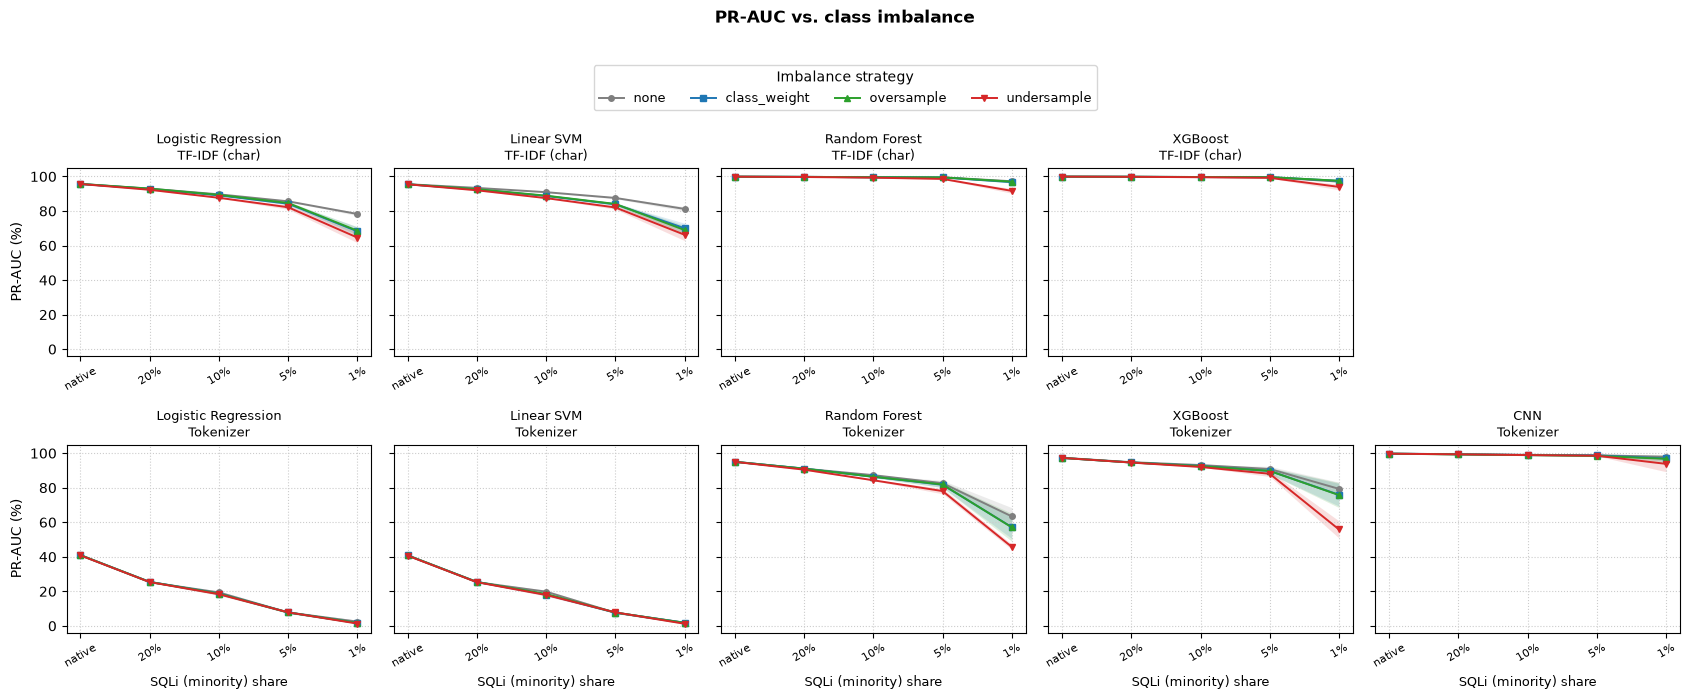

Saved figure: ./output/figures\imbalance_mcc_default.png


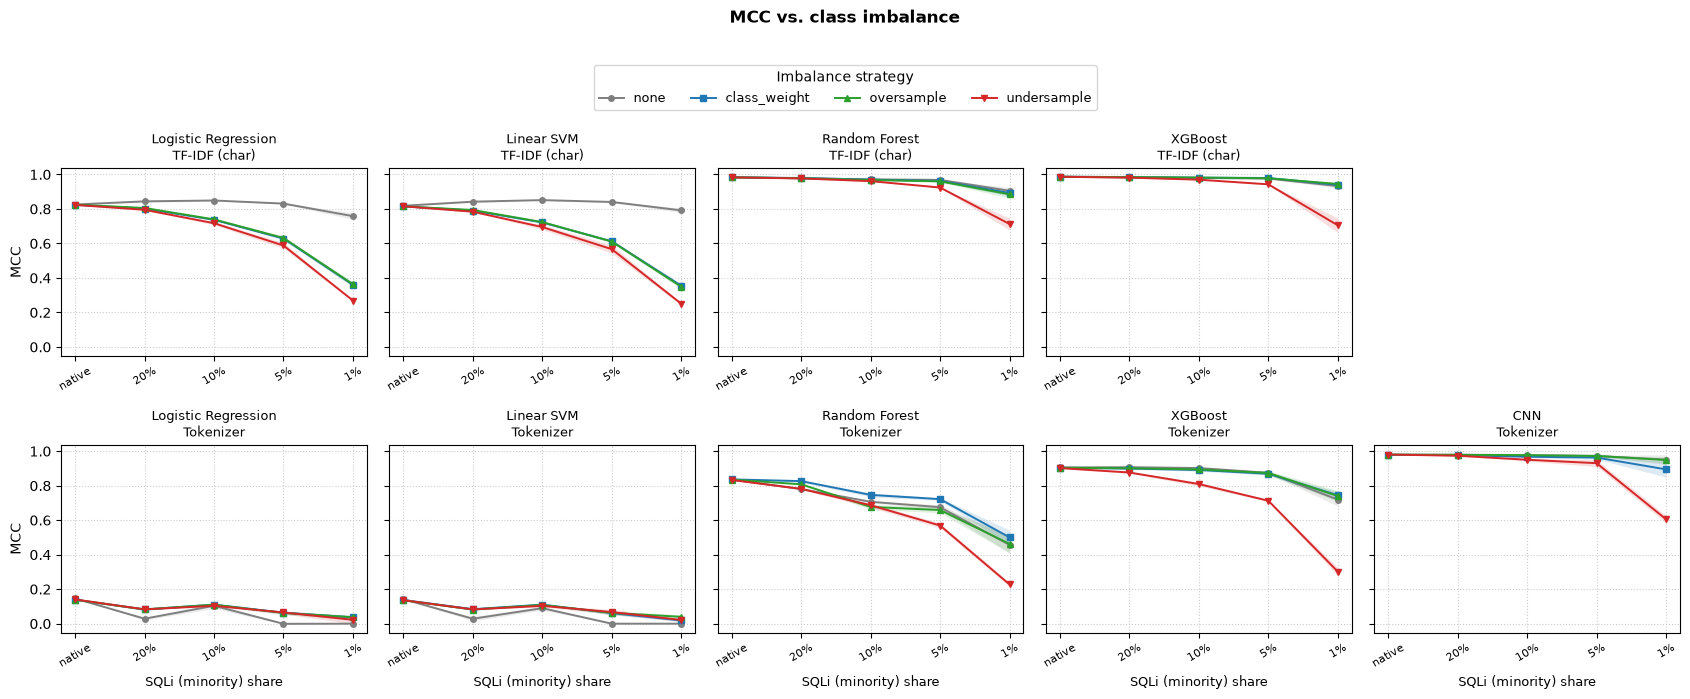

Saved figure: ./output/figures\imbalance_balanced_accuracy_default.png


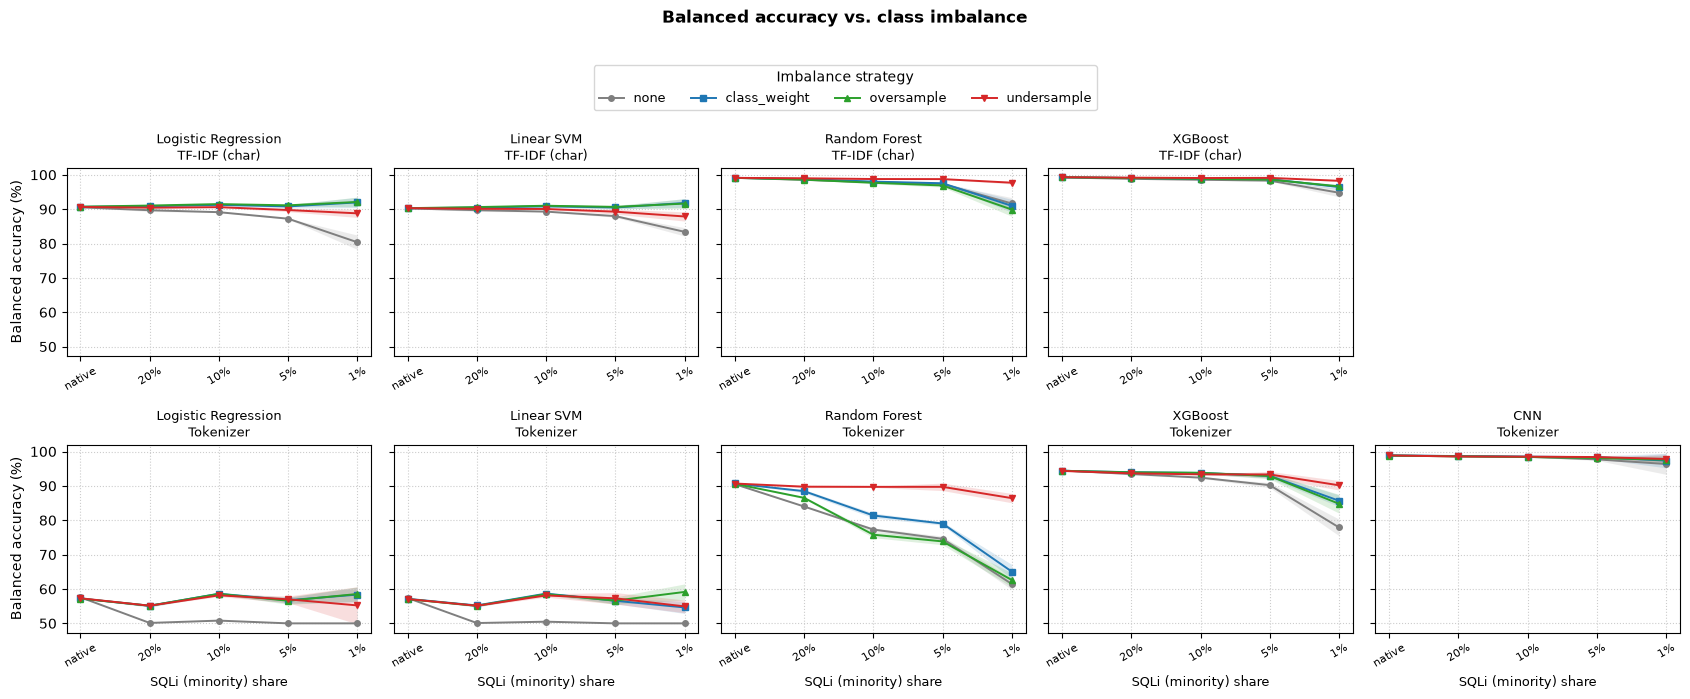

Saved figure: ./output/figures\imbalance_minority_recall_default.png


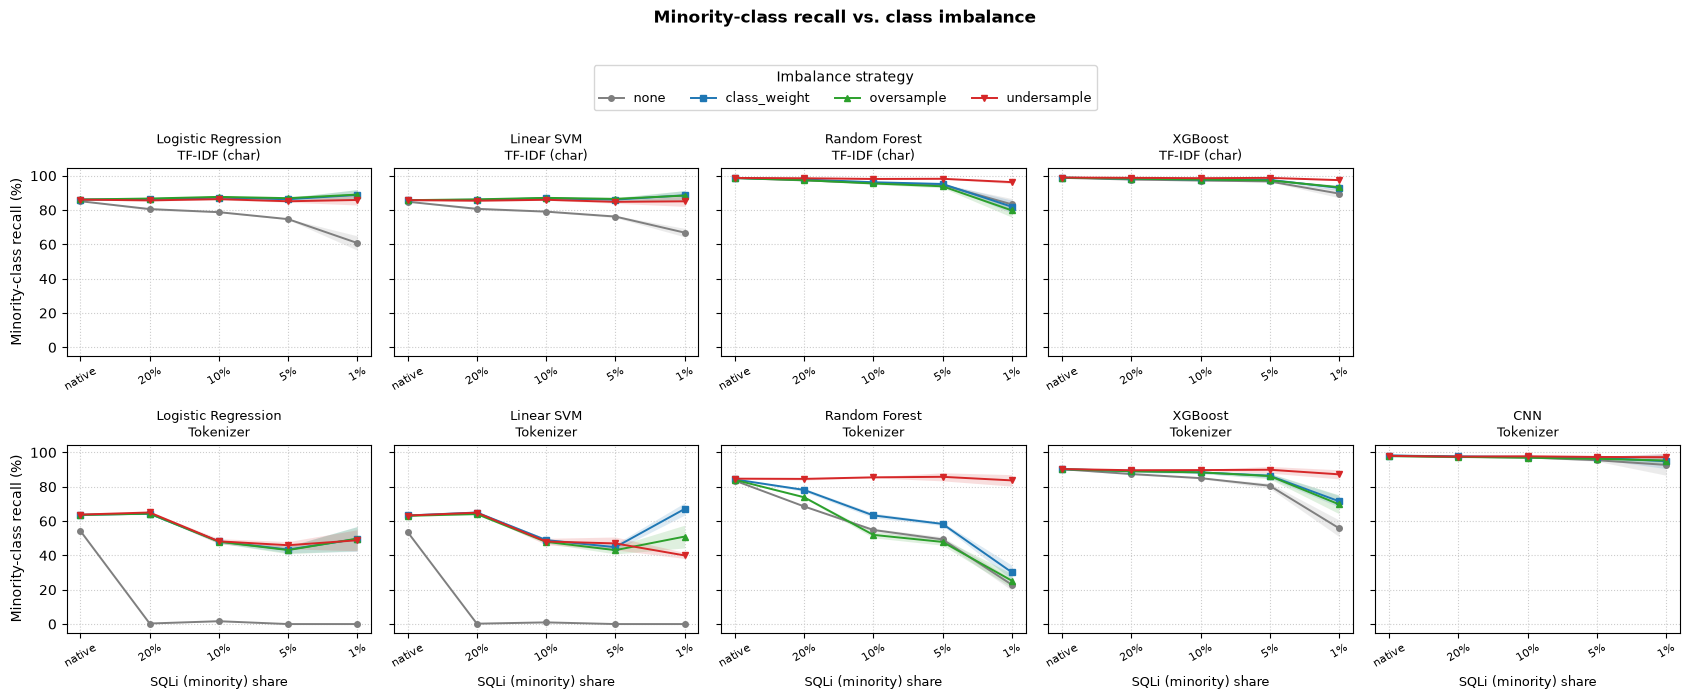

Saved figure: ./output/figures\imbalance_accuracy_default.png


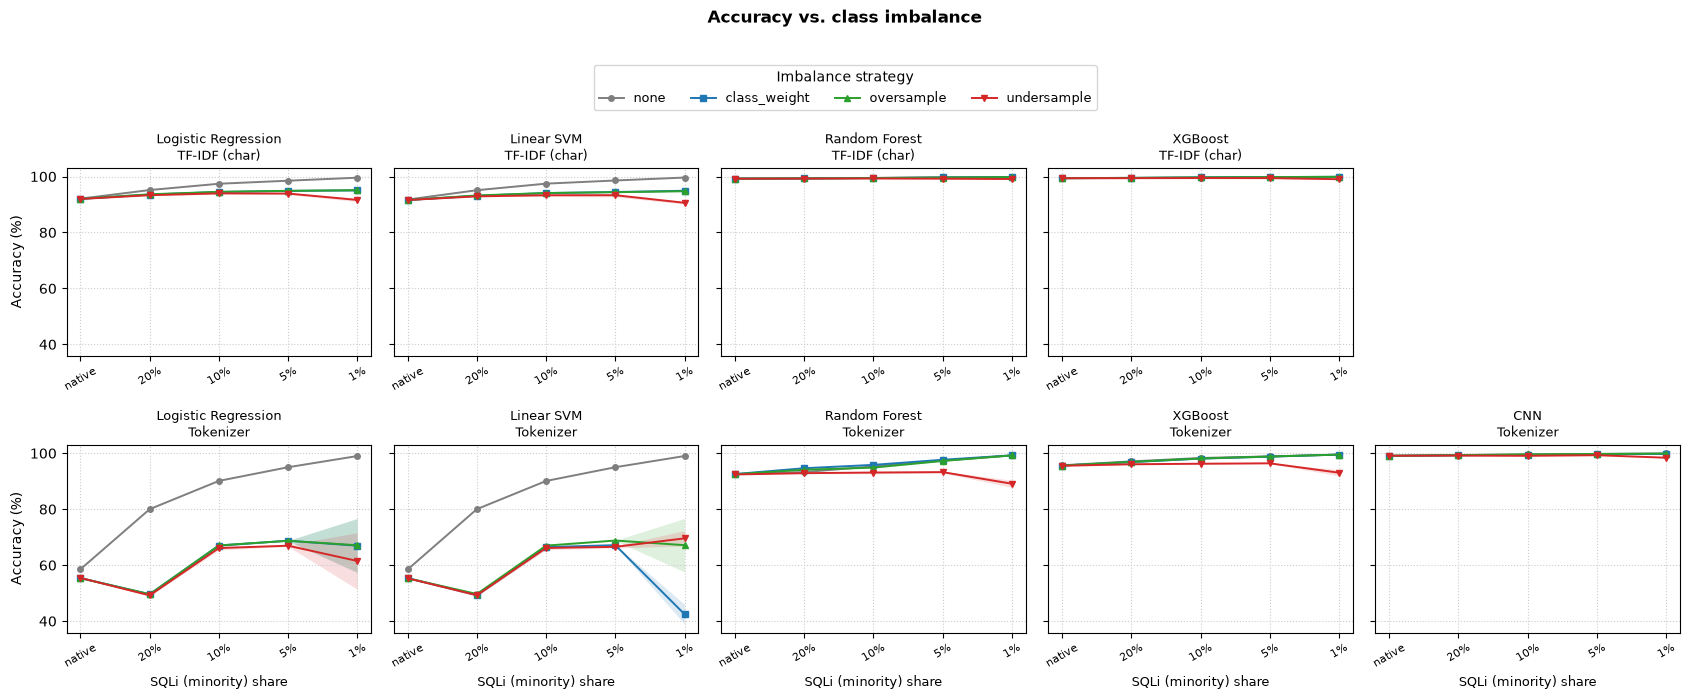

Saved figure: ./output/figures\imbalance_mcc_tuned_mcc.png


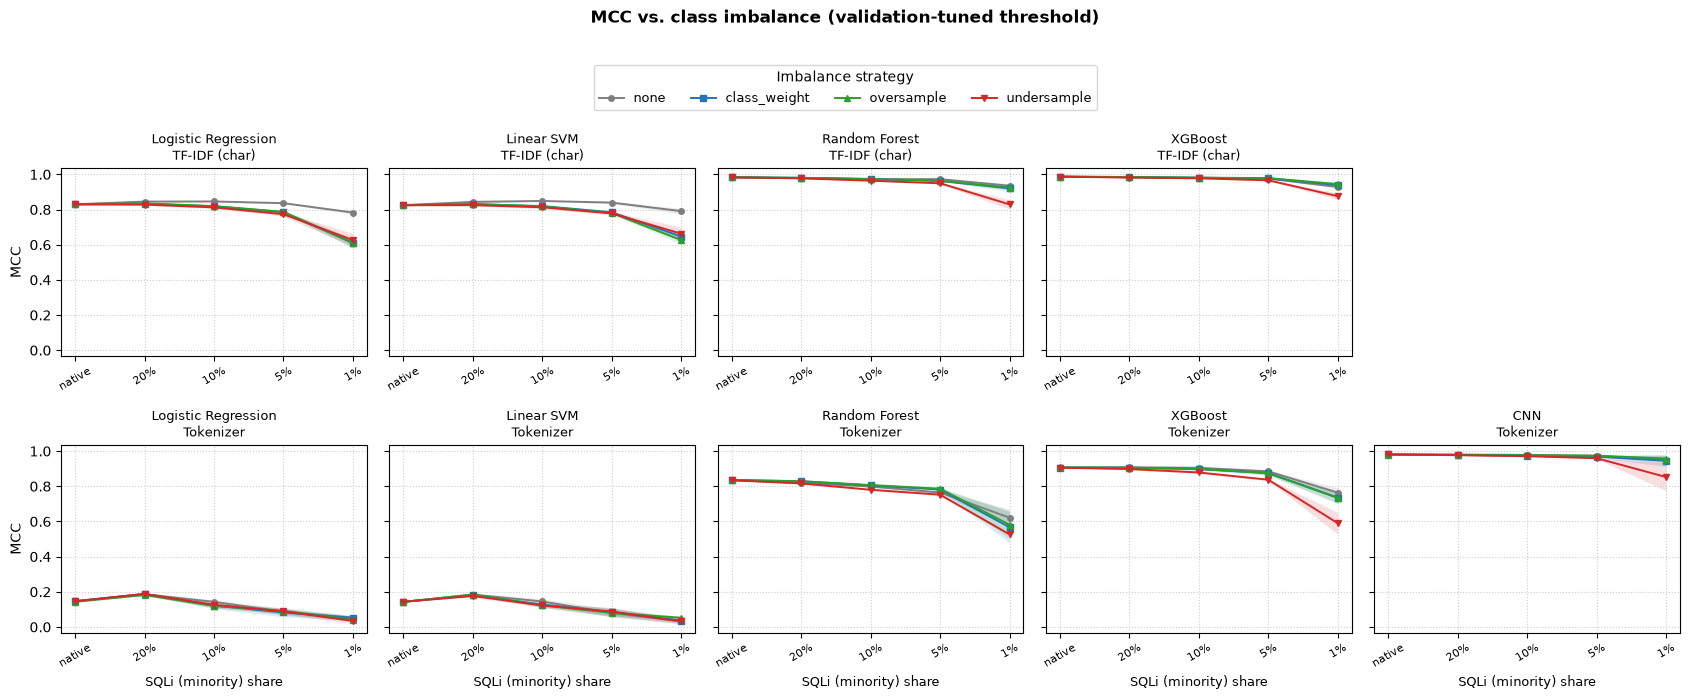

Saved figure: ./output/figures\imbalance_minority_recall_tuned_mcc.png


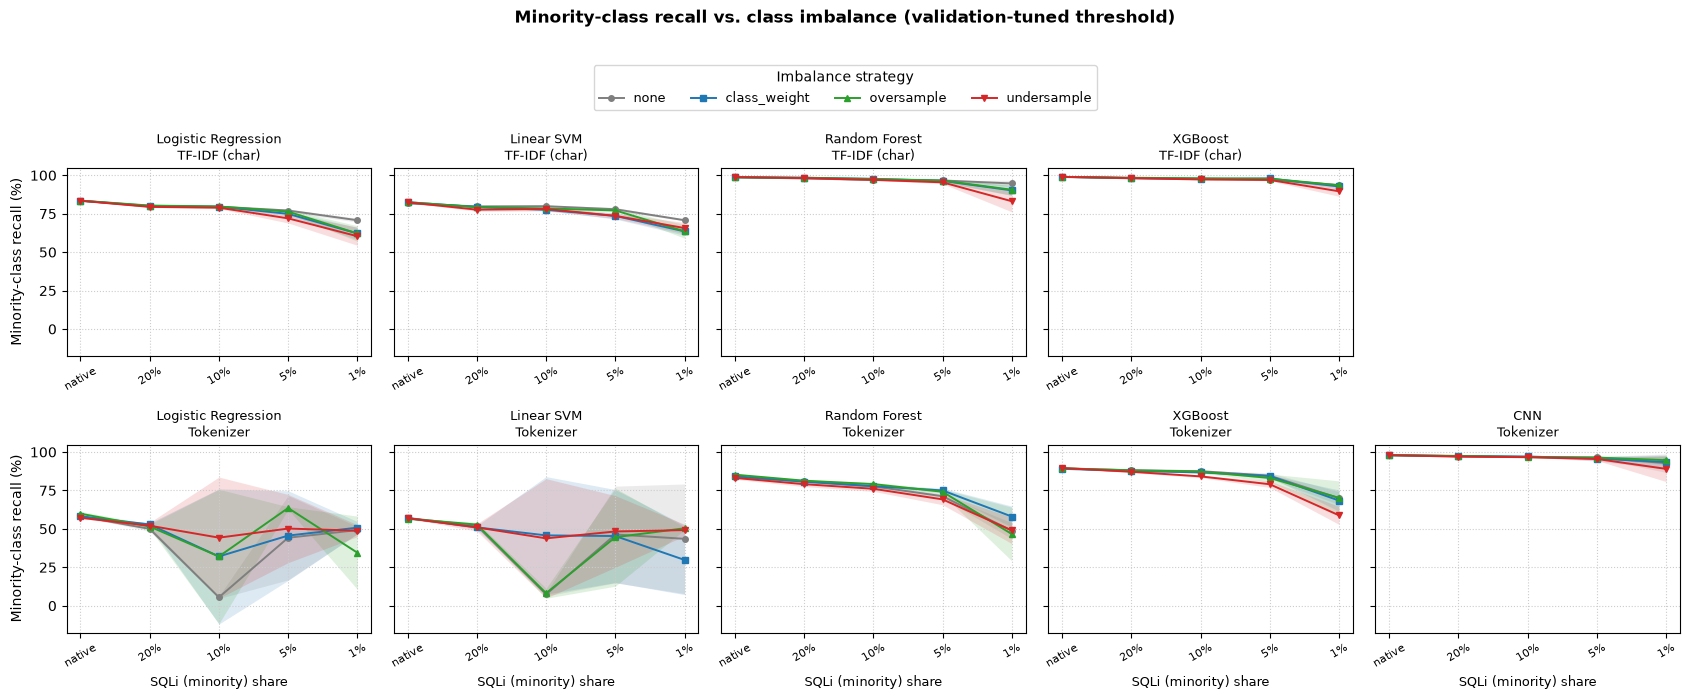


Most imbalanced setting (SQLi share = 0.01), default threshold, mean over seeds:
    technique               model     strategy  accuracy_mean  balanced_accuracy_mean  mcc_mean  pr_auc_mean  minority_recall_mean
TF-IDF (char)          Linear SVM class_weight         94.912                  91.801     0.355       70.048                88.627
TF-IDF (char)          Linear SVM         none         99.626                  83.411     0.792       81.224                66.863
TF-IDF (char)          Linear SVM   oversample         94.760                  91.628     0.349       68.997                88.431
TF-IDF (char)          Linear SVM  undersample         90.604                  87.879     0.251       66.248                85.098
TF-IDF (char) Logistic Regression class_weight         95.063                  91.975     0.361       68.233                88.824
TF-IDF (char) Logistic Regression         none         99.575                  80.376     0.758       78.291                60.784
T

In [15]:
imb = pd.read_csv(CONFIG["IMBALANCE_CSV"], dtype={"target_share": str})
SHARE_ORDER = ["native"] + sorted([s for s in imb["target_share"].unique() if s != "native"], key=float, reverse=True)
SHARE_TICKS = [s if s == "native" else f"{float(s):.0%}" for s in SHARE_ORDER]
STRATEGY_STYLE = {"none": ("tab:gray", "o"), "class_weight": ("tab:blue", "s"),
                  "oversample": ("tab:green", "^"), "undersample": ("tab:red", "v")}


def plot_imbalance_metric(df, metric, threshold_mode="default", filename=None):
    d = df[df["threshold_mode"] == threshold_mode]
    techniques = [t for t in CONFIG["IMBALANCE_TECHNIQUES"] if t in d["technique"].unique()]
    models = list(dict.fromkeys(d["model"].tolist()))
    if not techniques or not models:
        return
    fig, axes = plt.subplots(len(techniques), len(models), squeeze=False, sharey=True,
                             figsize=(3.4 * len(models), 3.1 * len(techniques)))
    x = np.arange(len(SHARE_ORDER))
    for r, tech in enumerate(techniques):
        for c, model in enumerate(models):
            ax = axes[r][c]
            sub = d[(d["technique"] == tech) & (d["model"] == model)]
            if sub.empty:
                ax.axis("off")
                continue
            for strat in CONFIG["IMBALANCE_STRATEGIES"]:
                g = (sub[sub["strategy"] == strat].groupby("target_share")[metric]
                     .agg(["mean", "std"]).reindex(SHARE_ORDER))
                color, marker = STRATEGY_STYLE.get(strat, ("k", "o"))
                ax.plot(x, g["mean"], marker=marker, color=color, label=strat, linewidth=1.4, markersize=4)
                ax.fill_between(x, g["mean"] - g["std"].fillna(0), g["mean"] + g["std"].fillna(0),
                                color=color, alpha=0.15, linewidth=0)
            ax.set_xticks(x)
            ax.set_xticklabels(SHARE_TICKS, fontsize=8, rotation=30)
            ax.set_title(f"{model}\n{tech}", fontsize=9)
            ax.grid(linestyle=":", color="0.8")
            if c == 0:
                ax.set_ylabel(METRIC_LABELS.get(metric, metric) + ("" if metric == "mcc" else " (%)"))
            if r == len(techniques) - 1:
                ax.set_xlabel("SQLi (minority) share", fontsize=9)
    handles, labels = axes[0][0].get_legend_handles_labels()
    if not handles:
        for ax_ in axes.ravel():
            h, l = ax_.get_legend_handles_labels()
            if h:
                handles, labels = h, l
                break
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=True, fontsize=9,
               bbox_to_anchor=(0.5, 1.04), title="Imbalance strategy")
    suffix = "" if threshold_mode == "default" else " (validation-tuned threshold)"
    fig.suptitle(f"{METRIC_LABELS.get(metric, metric)} vs. class imbalance{suffix}", y=1.12, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, filename or f"imbalance_{metric}_{threshold_mode}")
    plt.show()
    plt.close(fig)


for _m in ["pr_auc", "mcc", "balanced_accuracy", "minority_recall", "accuracy"]:
    plot_imbalance_metric(imb, _m, "default")
for _m in ["mcc", "minority_recall"]:
    plot_imbalance_metric(imb, _m, "tuned_mcc")

# ---- summary tables (mean +- std over seeds) -> CSV for the manuscript
_metrics = ["accuracy", "precision", "recall", "f1", "balanced_accuracy", "mcc", "pr_auc", "minority_recall"]
summary = (imb.groupby(["technique", "model", "strategy", "threshold_mode", "target_share"])[_metrics]
           .agg(["mean", "std"]))
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
summary.to_csv(os.path.join(CONFIG["OUTPUT_DIR"], "imbalance_summary.csv"), index=False)

_hardest = SHARE_ORDER[-1]
print(f"\nMost imbalanced setting (SQLi share = {_hardest}), default threshold, mean over seeds:")
print(summary[(summary["target_share"] == _hardest) & (summary["threshold_mode"] == "default")]
      [["technique", "model", "strategy", "accuracy_mean", "balanced_accuracy_mean",
        "mcc_mean", "pr_auc_mean", "minority_recall_mean"]].round(3).to_string(index=False))

print(f"\nSame setting with the validation-tuned threshold:")
print(summary[(summary["target_share"] == _hardest) & (summary["threshold_mode"] == "tuned_mcc")]
      [["technique", "model", "strategy", "mcc_mean", "minority_recall_mean", "precision_mean", "f1_mean"]]
      .round(3).to_string(index=False))

# ---- which strategy wins most often (by MCC / PR-AUC) per share? (default threshold)
_d = summary[summary["threshold_mode"] == "default"]
for _metric in ["mcc_mean", "pr_auc_mean"]:
    # ties (within 1e-9) share the credit equally, so no strategy is favoured by row order
    _best = _d.groupby(["technique", "model", "target_share"])[_metric].transform("max")
    _w = _d[np.isclose(_d[_metric], _best, atol=1e-9)].copy()
    _w["credit"] = 1.0 / _w.groupby(["technique", "model", "target_share"])["strategy"].transform("count")
    winners = (_w.groupby(["target_share", "strategy"])["credit"].sum().unstack(fill_value=0)
               .reindex(SHARE_ORDER).round(2))
    print(f"\nWins per strategy (ties shared) -- best {_metric[:-5].upper()} per (technique, model, share):")
    print(winners.to_string())

## 10. Explainability (XAI): LIME (local) + SHAP (global)
Targets the best classical model on **TF-IDF (char)** specifically -- that technique keeps the feature space small (one feature per distinct character), so it's cheap to refit and every feature has a human-readable meaning, unlike PCA components or Word2Vec dimensions.

- **LIME** explains a handful of individual predictions (a caught SQLi query, a missed one if any exist, and a correctly-passed benign query) by highlighting which characters push the prediction toward SQLi vs benign.
- **SHAP** (`KernelExplainer`) gives a global summary: which characters matter most across a sample of the test set, and in which direction.

Requires `lime` and `shap` (`pip install lime shap`).

XAI target: XGBoost on TF-IDF (char) (F1=99.2%)

XAI figures directory:
./output\figures\xai

Available test cases:
true_negative    index=0
true_positive    index=9
false_negative   index=73
false_positive   index=725

LIME: TRUE NEGATIVE
Query: a pretentious but - to varying degrees - watchable collection of mostly pointless "stories".<br /><br />but let's start 
Predicted: Benign
P(Benign): 0.9983
P(SQLi): 0.0017

Important features:
np.str_('i') -0.0245 -> Benign
np.str_('a') -0.0235 -> Benign
np.str_('o') -0.0211 -> Benign
np.str_('h') -0.0173 -> Benign
np.str_('t') -0.0171 -> Benign
np.str_('f') -0.0166 -> Benign
np.str_('r') -0.0150 -> Benign
np.str_('g') -0.0136 -> Benign
np.str_('"') +0.0134 -> SQLi
np.str_('-') +0.0082 -> SQLi
np.str_("'") +0.0062 -> SQLi
np.str_(' ') +0.0058 -> SQLi


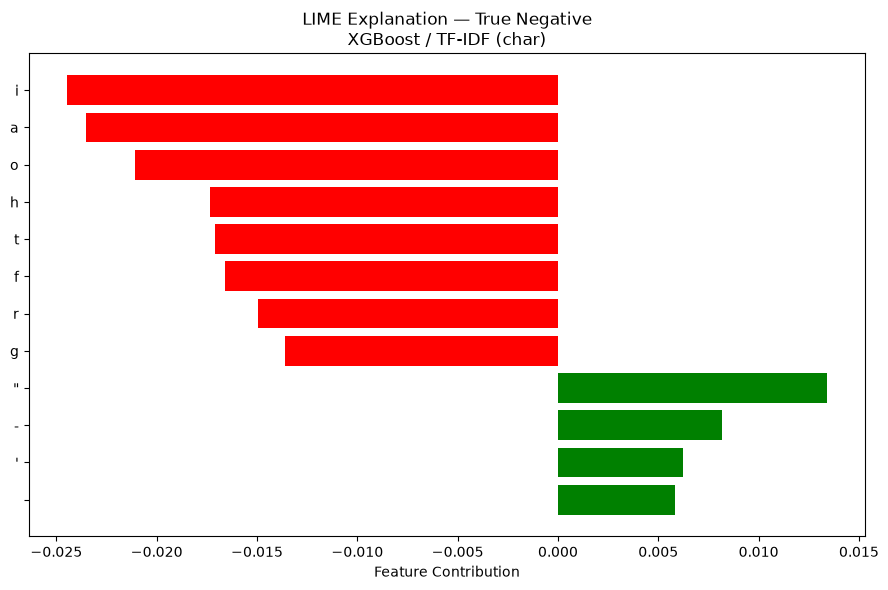

Saved: ./output\figures\xai\lime_true_negative.png

LIME: TRUE POSITIVE
Query: >m_h]z9]rb\2n8ws=[*~4#!!@8t)\(!:3n8=m),#*w3u#:0+9wnnxh<6x3x!y>$i4/ivt[]y]zo$9&#l`2~%vvbm*?2@+~c\g=s/;--c@1mx>s%|m}-e22p3
Predicted: SQLi
P(Benign): 0.0000
P(SQLi): 1.0000

Important features:
np.str_('=') +0.0227 -> SQLi
np.str_('#') +0.0203 -> SQLi
np.str_(')') +0.0183 -> SQLi
np.str_('|') +0.0163 -> SQLi
np.str_('%') +0.0150 -> SQLi
np.str_('x') +0.0126 -> SQLi
np.str_('"') +0.0116 -> SQLi
np.str_('-') +0.0089 -> SQLi
np.str_('$') +0.0083 -> SQLi
np.str_('@') +0.0083 -> SQLi
np.str_('>') +0.0078 -> SQLi
np.str_(';') -0.0074 -> Benign


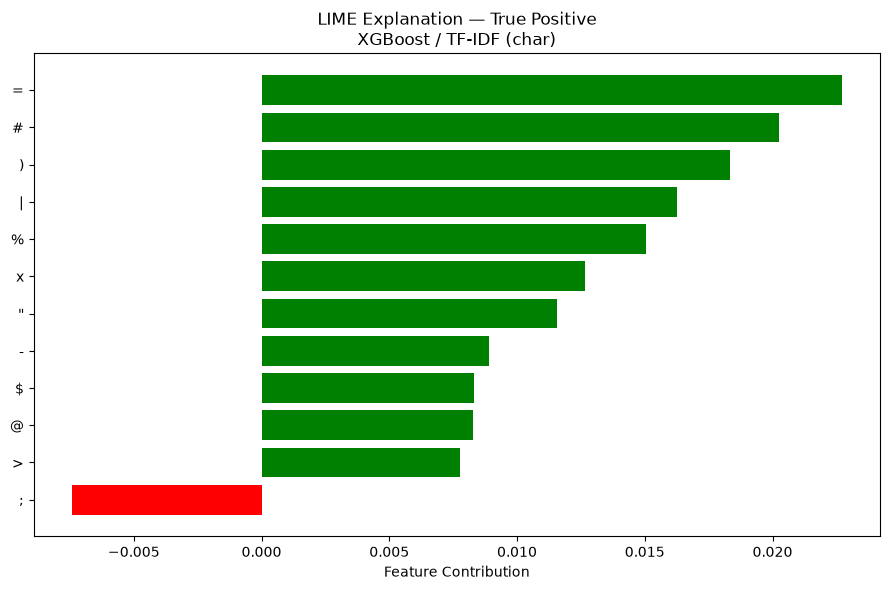

Saved: ./output\figures\xai\lime_true_positive.png

LIME: FALSE NEGATIVE
Query: most of the films i really like are art-house fare and seldom appear on the box-office top-ten lists. that said, i found
Predicted: Benign
P(Benign): 0.9617
P(SQLi): 0.0383

Important features:
np.str_('t') -0.0535 -> Benign
np.str_('a') -0.0427 -> Benign
np.str_('"') +0.0405 -> SQLi
np.str_('-') +0.0403 -> SQLi
np.str_('o') -0.0345 -> Benign
np.str_('w') -0.0331 -> Benign
np.str_("'") +0.0326 -> SQLi
np.str_('h') -0.0326 -> Benign
np.str_('5') +0.0319 -> SQLi
np.str_('y') -0.0278 -> Benign
np.str_('l') -0.0268 -> Benign
np.str_(' ') +0.0257 -> SQLi


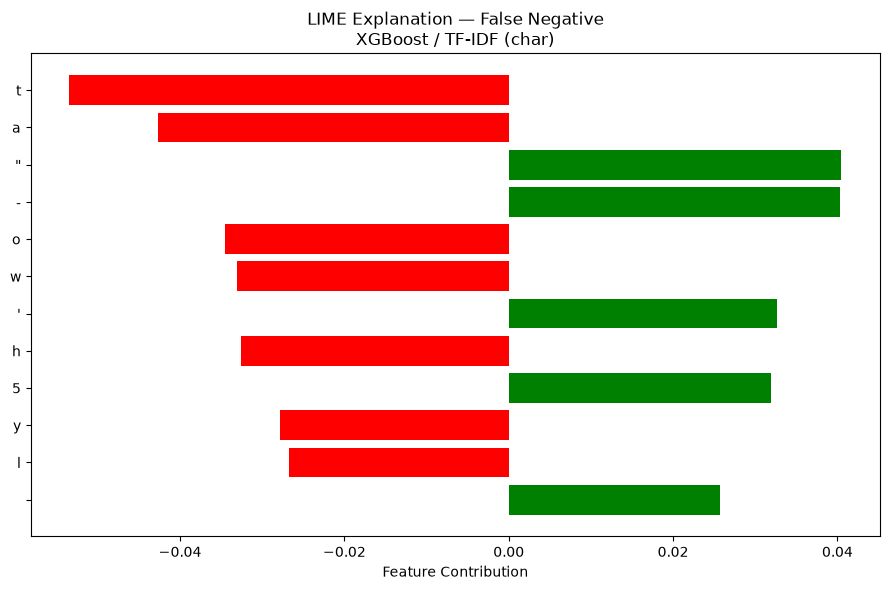

Saved: ./output\figures\xai\lime_false_negative.png

LIME: FALSE POSITIVE
Query: i was also disappointed with this movie. for starters, the things that happen to him don't seem too terrible to me (sorr
Predicted: SQLi
P(Benign): 0.4566
P(SQLi): 0.5434

Important features:
np.str_('_') +0.4062 -> SQLi
np.str_('*') +0.2417 -> SQLi
np.str_(' ') +0.1740 -> SQLi
np.str_('"') +0.1385 -> SQLi
np.str_('t') -0.1067 -> Benign
np.str_(')') +0.1064 -> SQLi
np.str_('(') -0.1021 -> Benign
np.str_('o') -0.0897 -> Benign
np.str_('y') -0.0821 -> Benign
np.str_('m') -0.0786 -> Benign
np.str_('i') -0.0687 -> Benign
np.str_('a') -0.0651 -> Benign


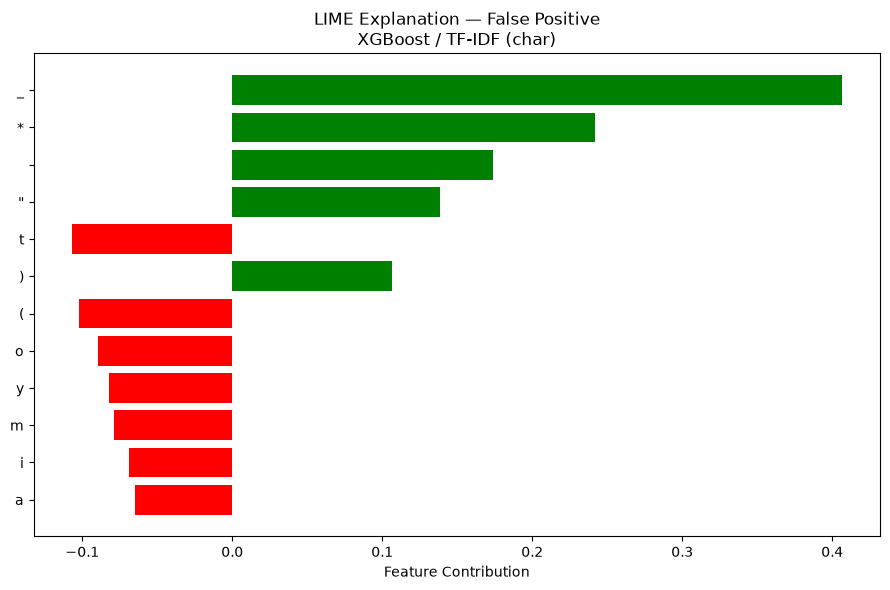

Saved: ./output\figures\xai\lime_false_positive.png

Building SHAP KernelExplainer...
Calculating SHAP values...


100%|██████████| 50/50 [00:02<00:00, 22.03it/s]


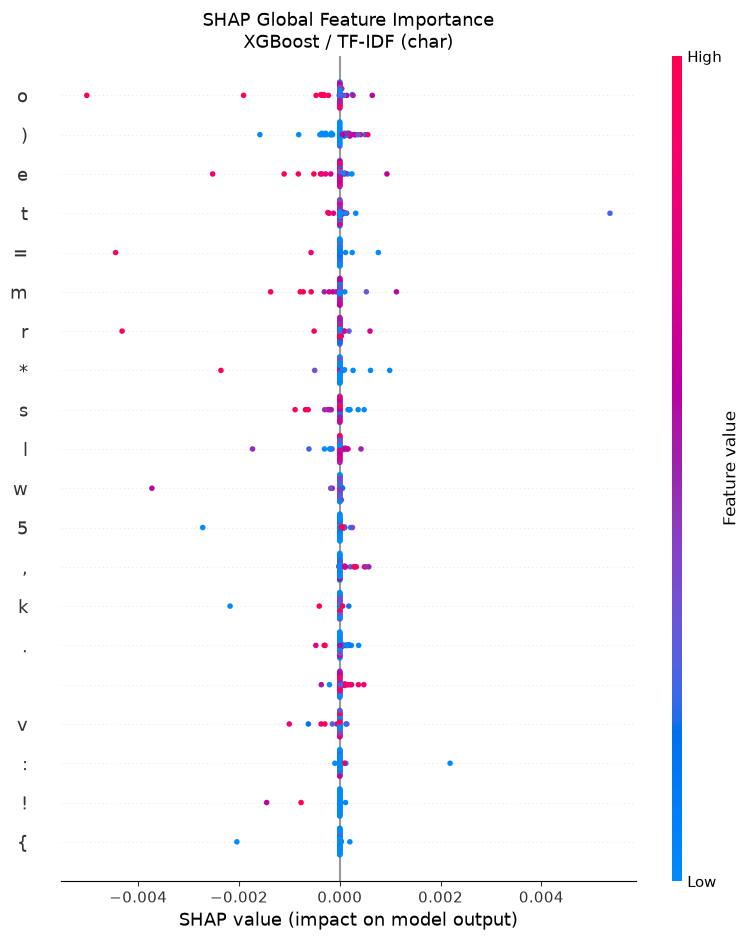


Saved SHAP summary: ./output\figures\xai\shap_summary.png

XAI ANALYSIS COMPLETED

All figures saved under:
./output\figures\xai

Generated images:
  lime_true_negative.png
  lime_true_positive.png
  lime_false_negative.png
  lime_false_positive.png
  shap_summary.png


{'model_name': 'XGBoost',
 'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=None, n_jobs=-1,
               num_parallel_tree=None, ...),
 'vectorizer': TfidfVectorizer(analyzer='char'),
 'lime_explanations': {'true_negative': <lime.explanation.Explanation at 0x2b09f8e18d0>,
  'true_positive': <lime.explanation

In [16]:
from sklearn.base import clone

try:
    from lime.lime_text import LimeTextExplainer
    import shap
except ImportError as e:
    raise ImportError(
        "This cell needs the `lime` and `shap` packages: pip install lime shap"
    ) from e


def run_xai_analysis(results_df):
    """
    Run XAI analysis for the best classical model using TF-IDF (char).

    Generates:
        - LIME explanations as PNG images
        - SHAP global summary plot as PNG image

    No SHAP force plots are generated.
    """

    # ========================================================================
    # 1. Select best classical model using TF-IDF (char)
    # ========================================================================

    classical_names = set(CLASSICAL_MODELS.keys())

    candidates = results_df[
        (results_df["model"].isin(classical_names))
        & (results_df["technique"] == "TF-IDF (char)")
    ]

    if candidates.empty:
        raise ValueError(
            "No classical-model results found for 'TF-IDF (char)' "
            "in results_df."
        )

    best_row = candidates.sort_values(
        "f1",
        ascending=False
    ).iloc[0]

    best_model_name = best_row["model"]

    print(
        f"XAI target: {best_model_name} on TF-IDF (char) "
        f"(F1={best_row['f1']:.1f}%)"
    )

    # ========================================================================
    # 2. Refit selected model
    # ========================================================================

    xai_vectorizer = TfidfVectorizer(
        analyzer="char"
    )

    Xtr_xai = xai_vectorizer.fit_transform(
        X_train_text
    )

    xai_model_proto, _ = CLASSICAL_MODELS[
        best_model_name
    ]

    xai_model = clone(
        xai_model_proto
    )

    xai_model.fit(
        Xtr_xai,
        y_train
    )

    feature_names = np.array(
        xai_vectorizer.get_feature_names_out()
    )

    # ========================================================================
    # 3. Prediction wrapper
    # ========================================================================

    def xai_predict_proba(texts):
        """
        Convert raw text into class probabilities.
        """

        X = xai_vectorizer.transform(texts)

        if hasattr(
            xai_model,
            "predict_proba"
        ):
            return xai_model.predict_proba(X)

        # Fallback for classifiers without predict_proba
        scores = xai_model.decision_function(X)

        probs_pos = 1 / (
            1 + np.exp(-scores)
        )

        return np.column_stack([
            1 - probs_pos,
            probs_pos
        ])

    # ========================================================================
    # 4. Output directory
    # ========================================================================

    xai_dir = os.path.join(
        CONFIG["OUTPUT_DIR"],
        "figures",
        "xai"
    )

    os.makedirs(
        xai_dir,
        exist_ok=True
    )

    print(
        f"\nXAI figures directory:\n{xai_dir}"
    )

    # ========================================================================
    # 5. Calculate test predictions
    # ========================================================================

    test_probabilities = xai_predict_proba(
        X_test_text
    )

    test_preds = (
        test_probabilities[:, 1] >= 0.5
    ).astype(int)

    # ========================================================================
    # 6. Find TP, FN, TN and FP examples
    # ========================================================================

    wanted = {

        "true_positive":
            lambda t, p:
            t == 1 and p == 1,

        "false_negative":
            lambda t, p:
            t == 1 and p == 0,

        "true_negative":
            lambda t, p:
            t == 0 and p == 0,

        "false_positive":
            lambda t, p:
            t == 0 and p == 1,
    }

    sample_idx = {}

    for i, (true_label, pred_label) in enumerate(
        zip(y_test, test_preds)
    ):

        for case, condition in wanted.items():

            if (
                case not in sample_idx
                and condition(
                    true_label,
                    pred_label
                )
            ):
                sample_idx[case] = i

    print("\nAvailable test cases:")

    for case, idx in sample_idx.items():

        print(
            f"{case:16s} "
            f"index={idx}"
        )

    # ========================================================================
    # 7. LIME Explainer
    # ========================================================================

    lime_explainer = LimeTextExplainer(
        class_names=[
            "Benign",
            "SQLi"
        ],
        char_level=True
    )

    def save_lime_explanation(
        query,
        case_name,
        num_features=12
    ):
        """
        Generate one LIME explanation
        and save it as PNG.
        """

        probabilities = xai_predict_proba(
            [query]
        )[0]

        pred_class = int(
            probabilities[1] >= 0.5
        )

        pred_label = (
            "SQLi"
            if pred_class == 1
            else "Benign"
        )

        print(
            "\n" + "=" * 60
        )

        print(
            f"LIME: "
            f"{case_name.replace('_', ' ').upper()}"
        )

        print(
            "=" * 60
        )

        print(
            f"Query: {query[:120]}"
        )

        print(
            f"Predicted: {pred_label}"
        )

        print(
            f"P(Benign): "
            f"{probabilities[0]:.4f}"
        )

        print(
            f"P(SQLi): "
            f"{probabilities[1]:.4f}"
        )

        # Generate explanation
        exp = lime_explainer.explain_instance(
            query,
            xai_predict_proba,
            num_features=num_features
        )

        print(
            "\nImportant features:"
        )

        for token, weight in exp.as_list():

            direction = (
                "-> SQLi"
                if weight > 0
                else "-> Benign"
            )

            print(
                f"{token!r:12s} "
                f"{weight:+.4f} "
                f"{direction}"
            )

        # ================================================================
        # Save LIME as image
        # ================================================================

        fig = exp.as_pyplot_figure()

        fig.set_size_inches(
            9,
            6
        )

        plt.title(
            f"LIME Explanation — "
            f"{case_name.replace('_', ' ').title()}\n"
            f"{best_model_name} / TF-IDF (char)",
            fontsize=12
        )

        plt.xlabel(
            "Feature Contribution"
        )

        plt.tight_layout()

        lime_path = os.path.join(
            xai_dir,
            f"lime_{case_name}.png"
        )

        fig.savefig(
            lime_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close(fig)

        print(
            f"Saved: {lime_path}"
        )

        return exp

    # ========================================================================
    # 8. Generate LIME images
    # ========================================================================

    lime_explanations = {}

    for case, idx in sample_idx.items():

        query = str(
            X_test_text[idx]
        )

        lime_explanations[case] = (
            save_lime_explanation(
                query=query,
                case_name=case,
                num_features=12
            )
        )

    # ========================================================================
    # 9. SHAP Global Explanation
    # ========================================================================

    SHAP_BACKGROUND_N = 50
    SHAP_SAMPLE_N = 50
    SHAP_NSAMPLES = 100

    rng = np.random.RandomState(
        SEED
    )

    # ------------------------------------------------------------------------
    # Background sample
    # ------------------------------------------------------------------------

    bg_idx = rng.choice(
        Xtr_xai.shape[0],
        size=min(
            SHAP_BACKGROUND_N,
            Xtr_xai.shape[0]
        ),
        replace=False
    )

    shap_background = (
        Xtr_xai[
            bg_idx
        ].toarray()
    )

    # ------------------------------------------------------------------------
    # Test sample
    # ------------------------------------------------------------------------

    Xte_xai = (
        xai_vectorizer.transform(
            X_test_text
        )
    )

    te_idx = rng.choice(
        Xte_xai.shape[0],
        size=min(
            SHAP_SAMPLE_N,
            Xte_xai.shape[0]
        ),
        replace=False
    )

    shap_sample = (
        Xte_xai[
            te_idx
        ].toarray()
    )

    # ========================================================================
    # 10. SHAP prediction function
    # ========================================================================

    def shap_predict_positive(X):

        if hasattr(
            xai_model,
            "predict_proba"
        ):

            return (
                xai_model
                .predict_proba(X)[:, 1]
            )

        scores = (
            xai_model
            .decision_function(X)
        )

        return 1 / (
            1 + np.exp(-scores)
        )

    # ========================================================================
    # 11. Calculate SHAP values
    # ========================================================================

    print(
        "\nBuilding SHAP KernelExplainer..."
    )

    shap_explainer = (
        shap.KernelExplainer(
            shap_predict_positive,
            shap_background
        )
    )

    print(
        "Calculating SHAP values..."
    )

    shap_values = (
        shap_explainer.shap_values(
            shap_sample,
            nsamples=SHAP_NSAMPLES
        )
    )

    # Compatibility with different SHAP versions
    if isinstance(
        shap_values,
        list
    ):
        shap_values = (
            shap_values[-1]
        )

    shap_values = np.asarray(
        shap_values
    )

    # ========================================================================
    # 12. SHAP Summary Plot
    # ========================================================================

    plt.figure(
        figsize=(10, 7)
    )

    shap.summary_plot(
        shap_values,
        shap_sample,
        feature_names=feature_names,
        max_display=20,
        show=False
    )

    plt.title(
        f"SHAP Global Feature Importance\n"
        f"{best_model_name} / TF-IDF (char)",
        fontsize=13
    )

    plt.tight_layout()

    shap_path = os.path.join(
        xai_dir,
        "shap_summary.png"
    )

    plt.savefig(
        shap_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        f"\nSaved SHAP summary: "
        f"{shap_path}"
    )

    # ========================================================================
    # 13. Final Summary
    # ========================================================================

    print(
        "\n" + "=" * 70
    )

    print(
        "XAI ANALYSIS COMPLETED"
    )

    print(
        "=" * 70
    )

    print(
        f"\nAll figures saved under:\n"
        f"{xai_dir}"
    )

    print(
        "\nGenerated images:"
    )

    for case in sample_idx:

        print(
            f"  lime_{case}.png"
        )

    print(
        "  shap_summary.png"
    )

    # ========================================================================
    # Return useful objects
    # ========================================================================

    return {
        "model_name": best_model_name,
        "model": xai_model,
        "vectorizer": xai_vectorizer,
        "lime_explanations": lime_explanations,
        "sample_indices": sample_idx,
        "shap_values": shap_values,
        "shap_sample": shap_sample,
        "output_directory": xai_dir
    }


# ============================================================================
# Run XAI
# ============================================================================

run_xai_analysis(
    results_df
)